# Maven Fuzzy Factory – E-commerce Data Analysis

## Project Overview
An end-to-end e-commerce data analytics project focused on analyzing website traffic, customer behavior, marketing performance, product sales, revenue trends, and conversion funnels.

## Objective
To extract actionable business insights using Python, Pandas, NumPy, Matplotlib, and Seaborn.

## Tools & Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Google Colab

In [ ]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Visualization settings
sns.set_style('whitegrid')

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
import os

# Display uploaded files
files = os.listdir('/content')

for file in files:
    if file.endswith('.csv'):
        print(file)

products.csv
website_sessions (1).csv
order_items.csv
orders.csv
website_pageviews (1).csv
order_item_refunds.csv


In [ ]:
# Load all six datasets

orders = pd.read_csv('/content/orders.csv')
order_items = pd.read_csv('/content/order_items.csv')
order_item_refunds = pd.read_csv('/content/order_item_refunds.csv')
products = pd.read_csv('/content/products.csv')
website_pageviews = pd.read_csv('/content/website_pageviews (1).csv')
website_sessions = pd.read_csv('/content/website_sessions (1).csv')

print("All six datasets loaded successfully!")

All six datasets loaded successfully!


In [ ]:
# Check the shape of all six datasets

datasets = {
    'Orders': orders,
    'Order Items': order_items,
    'Order Item Refunds': order_item_refunds,
    'Products': products,
    'Website Pageviews': website_pageviews,
    'Website Sessions': website_sessions
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows and {df.shape[1]} columns")

Orders: 32,313 rows and 8 columns
Order Items: 40,025 rows and 7 columns
Order Item Refunds: 1,731 rows and 5 columns
Products: 4 rows and 3 columns
Website Pageviews: 1,188,124 rows and 4 columns
Website Sessions: 472,871 rows and 9 columns


In [ ]:
# Display column names and data types of all datasets

for name, df in datasets.items():
    print(f"\n{'='*60}")
    print(f"DATASET: {name}")
    print(f"{'='*60}")
    print(df.info())


DATASET: Orders
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32313 entries, 0 to 32312
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   order_id            32313 non-null  int64  
 1   created_at          32313 non-null  object 
 2   website_session_id  32313 non-null  int64  
 3   user_id             32313 non-null  int64  
 4   primary_product_id  32313 non-null  int64  
 5   items_purchased     32313 non-null  int64  
 6   price_usd           32313 non-null  float64
 7   cogs_usd            32313 non-null  float64
dtypes: float64(2), int64(5), object(1)
memory usage: 2.0+ MB
None

DATASET: Order Items
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40025 entries, 0 to 40024
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_item_id    40025 non-null  int64  
 1   created_at       40025 non-null  object 
 2  

In [ ]:
# Convert created_at columns into datetime format

for df in datasets.values():
    df['created_at'] = pd.to_datetime(df['created_at'])

print("Date columns converted successfully!")

Date columns converted successfully!


In [ ]:
# Verify date column data types

for name, df in datasets.items():
    print(f"{name}: {df['created_at'].dtype}")

Orders: datetime64[ns]
Order Items: datetime64[ns]
Order Item Refunds: datetime64[ns]
Products: datetime64[ns]
Website Pageviews: datetime64[ns]
Website Sessions: datetime64[ns]


In [ ]:
# Check missing values in all six datasets

for name, df in datasets.items():
    print(f"\n{'='*50}")
    print(f"Missing Values - {name}")
    print(f"{'='*50}")

    missing = df.isnull().sum()
    print(missing[missing > 0])


Missing Values - Orders
Series([], dtype: int64)

Missing Values - Order Items
Series([], dtype: int64)

Missing Values - Order Item Refunds
Series([], dtype: int64)

Missing Values - Products
Series([], dtype: int64)

Missing Values - Website Pageviews
Series([], dtype: int64)

Missing Values - Website Sessions
utm_source      83328
utm_campaign    83328
utm_content     83328
http_referer    39917
dtype: int64


In [ ]:
# Check duplicate records in all six datasets

for name, df in datasets.items():
    duplicates = df.duplicated().sum()

    print(f"{name}: {duplicates:,} duplicate rows")

Orders: 0 duplicate rows
Order Items: 0 duplicate rows
Order Item Refunds: 0 duplicate rows
Products: 0 duplicate rows
Website Pageviews: 0 duplicate rows
Website Sessions: 0 duplicate rows


In [ ]:
# Check duplicate primary keys

primary_keys = {
    'Orders': (orders, 'order_id'),
    'Order Items': (order_items, 'order_item_id'),
    'Order Item Refunds': (order_item_refunds, 'order_item_refund_id'),
    'Products': (products, 'product_id'),
    'Website Pageviews': (website_pageviews, 'website_pageview_id'),
    'Website Sessions': (website_sessions, 'website_session_id')
}

for name, (df, key) in primary_keys.items():
    duplicates = df[key].duplicated().sum()
    print(f"{name}: {duplicates:,} duplicate {key} values")

Orders: 0 duplicate order_id values
Order Items: 0 duplicate order_item_id values
Order Item Refunds: 0 duplicate order_item_refund_id values
Products: 0 duplicate product_id values
Website Pageviews: 0 duplicate website_pageview_id values
Website Sessions: 0 duplicate website_session_id values


In [ ]:
# Check financial columns for invalid values

financial_columns = {
    'Orders': (orders, ['price_usd', 'cogs_usd']),
    'Order Items': (order_items, ['price_usd', 'cogs_usd']),
    'Order Item Refunds': (order_item_refunds, ['refund_amount_usd'])
}

for name, (df, columns) in financial_columns.items():
    print(f"\n{name}")

    for col in columns:
        invalid = (df[col] <= 0).sum()
        print(f"{col}: {invalid:,} zero or negative values")


Orders
price_usd: 0 zero or negative values
cogs_usd: 0 zero or negative values

Order Items
price_usd: 0 zero or negative values
cogs_usd: 0 zero or negative values

Order Item Refunds
refund_amount_usd: 0 zero or negative values


In [ ]:
# Referential integrity validation

checks = {
    'Orders → Website Sessions':
        (~orders['website_session_id'].isin(website_sessions['website_session_id'])).sum(),

    'Order Items → Orders':
        (~order_items['order_id'].isin(orders['order_id'])).sum(),

    'Refunds → Order Items':
        (~order_item_refunds['order_item_id'].isin(order_items['order_item_id'])).sum(),

    'Website Pageviews → Website Sessions':
        (~website_pageviews['website_session_id'].isin(website_sessions['website_session_id'])).sum(),

    'Orders → Products':
        (~orders['primary_product_id'].isin(products['product_id'])).sum()
}

for relationship, unmatched in checks.items():
    print(f"{relationship}: {unmatched:,} unmatched records")

Orders → Website Sessions: 0 unmatched records
Order Items → Orders: 0 unmatched records
Refunds → Order Items: 0 unmatched records
Website Pageviews → Website Sessions: 0 unmatched records
Orders → Products: 0 unmatched records


In [ ]:
# Display first five records from Orders

orders.head()


,order_id,created_at,website_session_id,user_id,primary_product_id,items_purchased,price_usd,cogs_usd
0,1,2012-03-19 10:42:46,20,20,1,1,49.99,19.49
1,2,2012-03-19 19:27:37,104,104,1,1,49.99,19.49
2,3,2012-03-20 06:44:45,147,147,1,1,49.99,19.49
3,4,2012-03-20 09:41:45,160,160,1,1,49.99,19.49
4,5,2012-03-20 11:28:15,177,177,1,1,49.99,19.49


In [ ]:
order_items.head()

,order_item_id,created_at,order_id,product_id,is_primary_item,price_usd,cogs_usd
0,1,2012-03-19 10:42:46,1,1,1,49.99,19.49
1,2,2012-03-19 19:27:37,2,1,1,49.99,19.49
2,3,2012-03-20 06:44:45,3,1,1,49.99,19.49
3,4,2012-03-20 09:41:45,4,1,1,49.99,19.49
4,5,2012-03-20 11:28:15,5,1,1,49.99,19.49


In [ ]:
order_item_refunds.head()

,order_item_refund_id,created_at,order_item_id,order_id,refund_amount_usd
0,1,2012-04-06 11:32:43,57,57,49.99
1,2,2012-04-13 01:09:43,74,74,49.99
2,3,2012-04-15 07:03:48,71,71,49.99
3,4,2012-04-17 20:00:37,118,118,49.99
4,5,2012-04-22 20:53:49,116,116,49.99


In [ ]:
products.head()

,product_id,created_at,product_name
0,1,2012-03-19 08:00:00,The Original Mr. Fuzzy
1,2,2013-01-06 13:00:00,The Forever Love Bear
2,3,2013-12-12 09:00:00,The Birthday Sugar Panda
3,4,2014-02-05 10:00:00,The Hudson River Mini bear


In [ ]:
website_pageviews.head()

,website_pageview_id,created_at,website_session_id,pageview_url
0,1,2012-03-19 08:04:16,1,/home
1,2,2012-03-19 08:16:49,2,/home
2,3,2012-03-19 08:26:55,3,/home
3,4,2012-03-19 08:37:33,4,/home
4,5,2012-03-19 09:00:55,5,/home


In [ ]:
website_sessions.head()

,website_session_id,created_at,user_id,is_repeat_session,utm_source,utm_campaign,utm_content,device_type,http_referer
0,1,2012-03-19 08:04:16,1,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com
1,2,2012-03-19 08:16:49,2,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
2,3,2012-03-19 08:26:55,3,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
3,4,2012-03-19 08:37:33,4,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com
4,5,2012-03-19 09:00:55,5,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com


In [ ]:
# Python Data Quality Assessment Summary

quality_results = []

for name, df in datasets.items():

    # Identify primary key
    key = primary_keys[name][1]

    quality_results.append({
        'Dataset': name,
        'Total Rows': len(df),
        'Total Columns': len(df.columns),
        'Missing Values': df.isnull().sum().sum(),
        'Duplicate Rows': df.duplicated().sum(),
        'Duplicate Primary Keys': df[key].duplicated().sum(),
        'Date Data Type': str(df['created_at'].dtype)
    })

quality_summary = pd.DataFrame(quality_results)

quality_summary

,Dataset,Total Rows,Total Columns,Missing Values,Duplicate Rows,Duplicate Primary Keys,Date Data Type
0,Orders,32313,8,0,0,0,datetime64[ns]
1,Order Items,40025,7,0,0,0,datetime64[ns]
2,Order Item Refunds,1731,5,0,0,0,datetime64[ns]
3,Products,4,3,0,0,0,datetime64[ns]
4,Website Pageviews,1188124,4,0,0,0,datetime64[ns]
5,Website Sessions,472871,9,289901,0,0,datetime64[ns]


# 5. PYTHON EXPLORATORY DATA ANALYSIS (EDA)
## 5.1 Orders Dataset – Exploratory Data Analysis

### EDA 5.1.1 – Orders Dataset: Business Understanding

**Business Context:**

The company wants to understand its order-level performance, customer purchasing patterns and financial performance.

**Business Question:**

What are the key characteristics of customer orders, including order value, items purchased, cost of goods sold and profitability?

**Objective:**

To examine the distribution of order metrics, identify purchasing patterns, understand financial characteristics and establish a foundation for deeper business analysis.

EDA 5.1.2 – Dataset Overview and Structure
Business Question: What is the structure of the Orders dataset, and what information is available for analyzing order-level business performance?

Objective: Understand the dataset's dimensions, columns, data types and overall structure before conducting deeper statistical analysis.

In [ ]:
# EDA 5.1.2: Orders Dataset Overview

print("Dataset Shape:", orders.shape)

print("\nColumn Names:")
print(orders.columns.tolist())

print("\nDataset Information:")
orders.info()

Dataset Shape: (32313, 10)

Column Names:
['order_id', 'created_at', 'website_session_id', 'user_id', 'primary_product_id', 'items_purchased', 'price_usd', 'cogs_usd', 'gross_profit', 'gross_margin_pct']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32313 entries, 0 to 32312
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   order_id            32313 non-null  int64         
 1   created_at          32313 non-null  datetime64[ns]
 2   website_session_id  32313 non-null  int64         
 3   user_id             32313 non-null  int64         
 4   primary_product_id  32313 non-null  int64         
 5   items_purchased     32313 non-null  int64         
 6   price_usd           32313 non-null  float64       
 7   cogs_usd            32313 non-null  float64       
 8   gross_profit        32313 non-null  float64       
 9   gross_margin_pct    32313 non-null  float64 

EDA 5.1.3 – Order Distribution Analysis
Business Question: How are customer orders distributed in terms of items purchased, order value, cost of goods sold, and gross profit?

Objective: Understand typical order characteristics and identify unusual values or patterns.

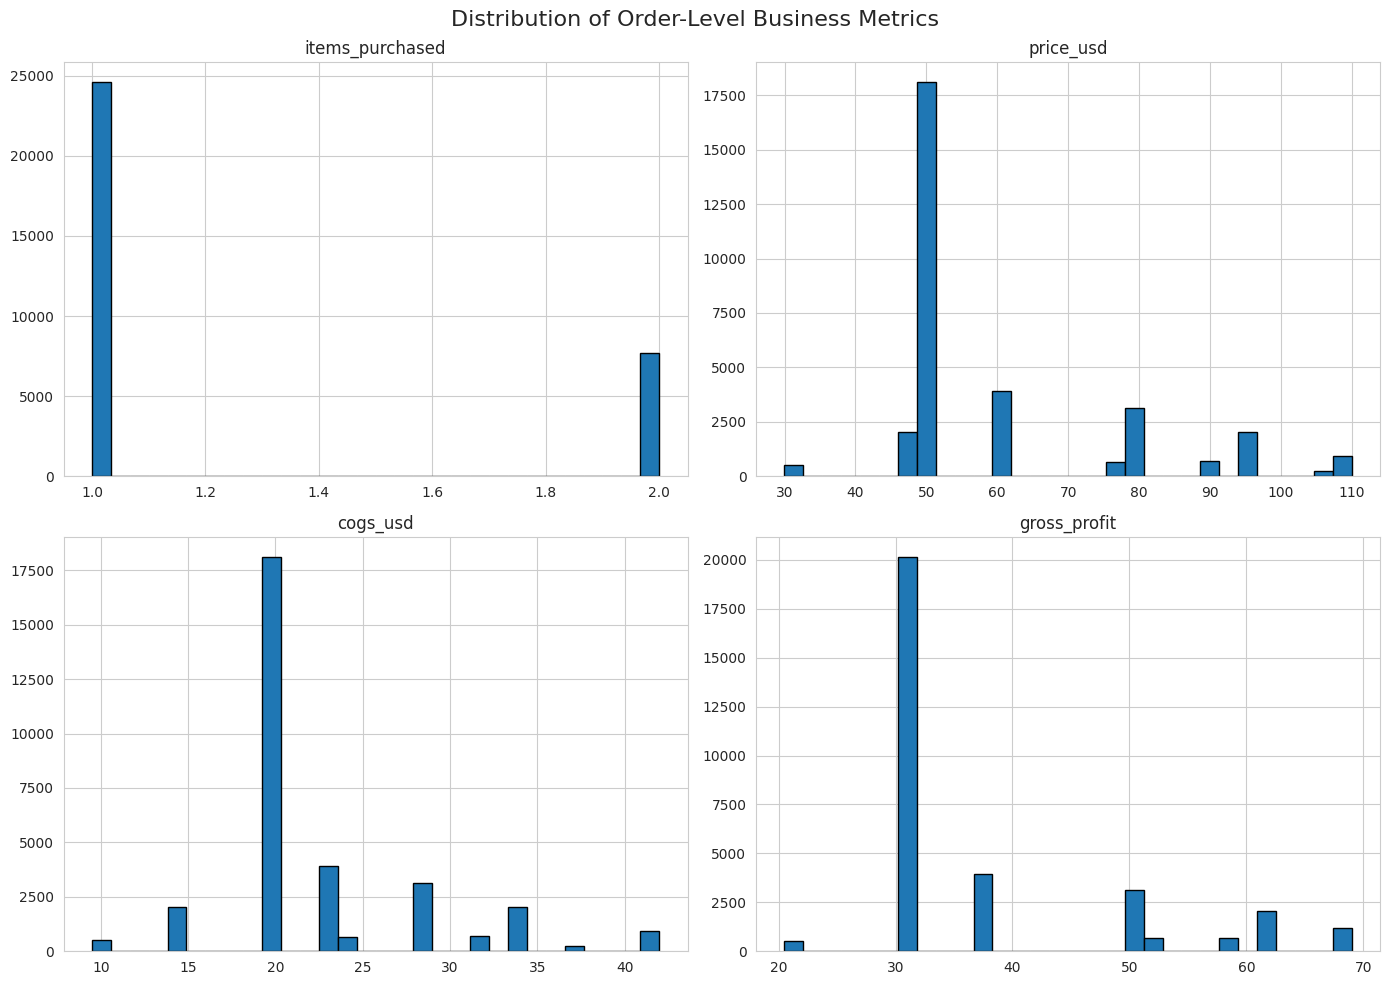

In [ ]:
# EDA 5.1.3: Order Distribution Analysis

import matplotlib.pyplot as plt
import seaborn as sns

order_metrics = [
    'items_purchased',
    'price_usd',
    'cogs_usd',
    'gross_profit'
]

orders[order_metrics].hist(
    figsize=(14, 10),
    bins=30,
    edgecolor='black'
)

plt.suptitle('Distribution of Order-Level Business Metrics',
             fontsize=16)

plt.tight_layout()
plt.show()

EDA 5.1.4 – Outlier Detection in Orders
Business Question: Are there unusually high or low order values, costs, or profits that could influence business performance analysis?

Objective: Identify potential outliers in order-level financial metrics using the Interquartile Range (IQR) method.

In [ ]:
# EDA 5.1.4: Outlier Detection using IQR

financial_columns = [
    'price_usd',
    'cogs_usd',
    'gross_profit'
]

outlier_summary = []

for col in financial_columns:

    Q1 = orders[col].quantile(0.25)
    Q3 = orders[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = orders[
        (orders[col] < lower_bound) |
        (orders[col] > upper_bound)
    ]

    outlier_summary.append({
        'Metric': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers),
        'Outlier Percentage': round(
            len(outliers) / len(orders) * 100, 2
        )
    })

outlier_summary_df = pd.DataFrame(outlier_summary)

outlier_summary_df.round(2)

,Metric,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,price_usd,49.99,59.99,10.0,34.99,74.99,8246,25.52
1,cogs_usd,19.49,22.49,3.0,14.99,26.99,9623,29.78
2,gross_profit,30.50,37.50,7.0,20.00,48.00,7712,23.87


EDA 5.1.5 – Financial Outlier Visualization
Business Question: Are there extreme values in order revenue, cost of goods sold, and gross profit?

Objective: Use box plots to visualize the spread of financial metrics and identify potential extreme observations.

### EDA 5.1.5 – Financial Outlier Visualization

**Business Context:**
The business wants to understand the variation in order-level financial performance.

**Business Question:**
Are there extreme values in order revenue, cost of goods sold, and gross profit?

**Objective:**
Visualize the distribution and potential extreme values using box plots.

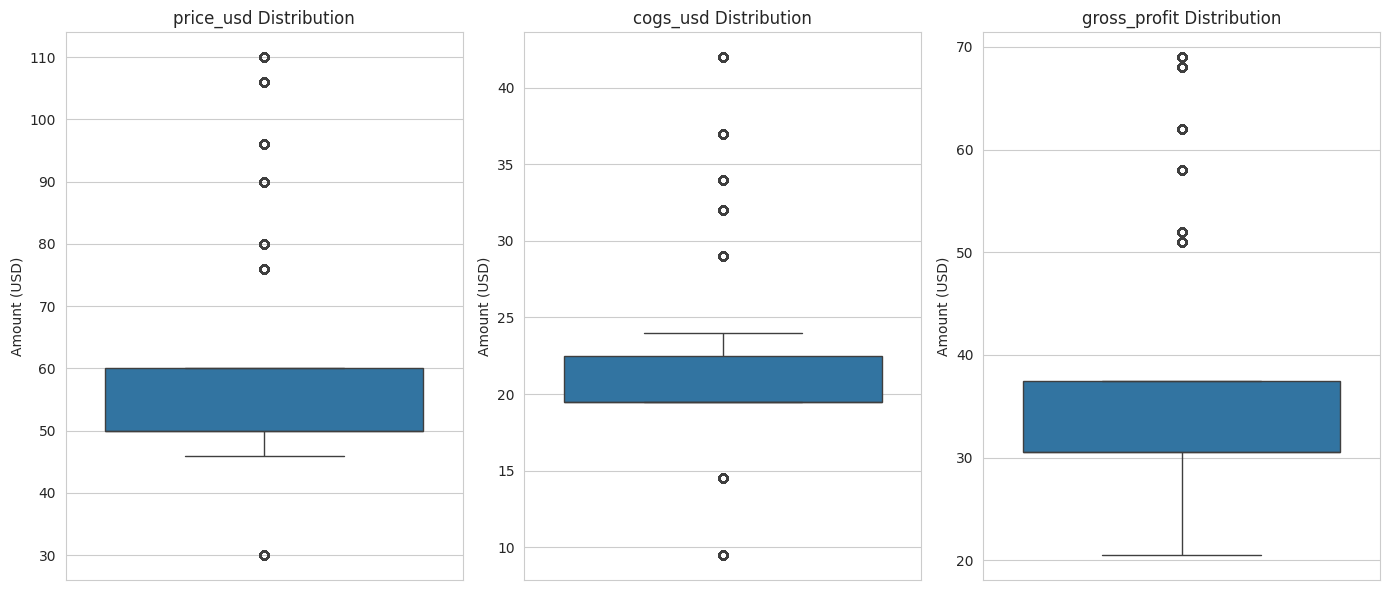

In [ ]:
# EDA 5.1.5: Financial Outlier Visualization

financial_columns = [
    'price_usd',
    'cogs_usd',
    'gross_profit'
]

plt.figure(figsize=(14, 6))

for i, col in enumerate(financial_columns, 1):
    plt.subplot(1, 3, i)

    sns.boxplot(y=orders[col])

    plt.title(f'{col} Distribution')
    plt.ylabel('Amount (USD)')

plt.tight_layout()
plt.show()


### EDA 5.1.6 – Correlation Analysis of Order Metrics

**Business Context:**
The business wants to understand the relationships between order revenue, costs, and profitability.

**Business Question:**
How strongly are order value, cost of goods sold, and gross profit related?

**Objective:**
Calculate and visualize correlations between financial metrics to understand their relationships.

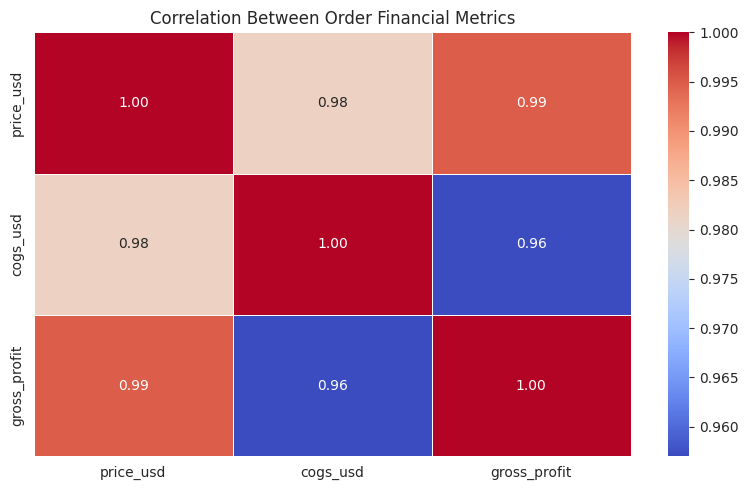

In [ ]:
# EDA 5.1.6: Correlation Analysis

correlation_data = orders[
    ['price_usd', 'cogs_usd', 'gross_profit']
]

correlation_matrix = correlation_data.corr()

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Between Order Financial Metrics')
plt.tight_layout()
plt.show()

### EDA 5.1.7 – Monthly Order and Revenue Trends

**Business Context:**
Management wants to monitor monthly order activity and financial performance.

**Business Question:**
How do the number of orders, revenue, and gross profit change month over month?

**Objective:**
Analyze monthly order volume, revenue, and gross profit to identify business growth patterns and fluctuations.

In [ ]:
# EDA 5.1.7: Monthly Order and Revenue Trends

monthly_orders = (
    orders.set_index('created_at')
    .resample('MS')
    .agg(
        Total_Orders=('order_id', 'count'),
        Total_Revenue=('price_usd', 'sum'),
        Total_Gross_Profit=('gross_profit', 'sum')
    )
    .reset_index()
)

monthly_orders.head()

,created_at,Total_Orders,Total_Revenue,Total_Gross_Profit
0,2012-03-01,60,2999.40,1830.0
1,2012-04-01,99,4949.01,3019.5
2,2012-05-01,108,5398.92,3294.0
3,2012-06-01,140,6998.60,4270.0
4,2012-07-01,169,8448.31,5154.5


### EDA 5.1.8 – Monthly Business Performance Visualization

**Business Question:**
What are the monthly trends in order volume, revenue and gross profit?

**Objective:**
Visualize monthly order volume, revenue and gross profit to identify business growth patterns and fluctuations.

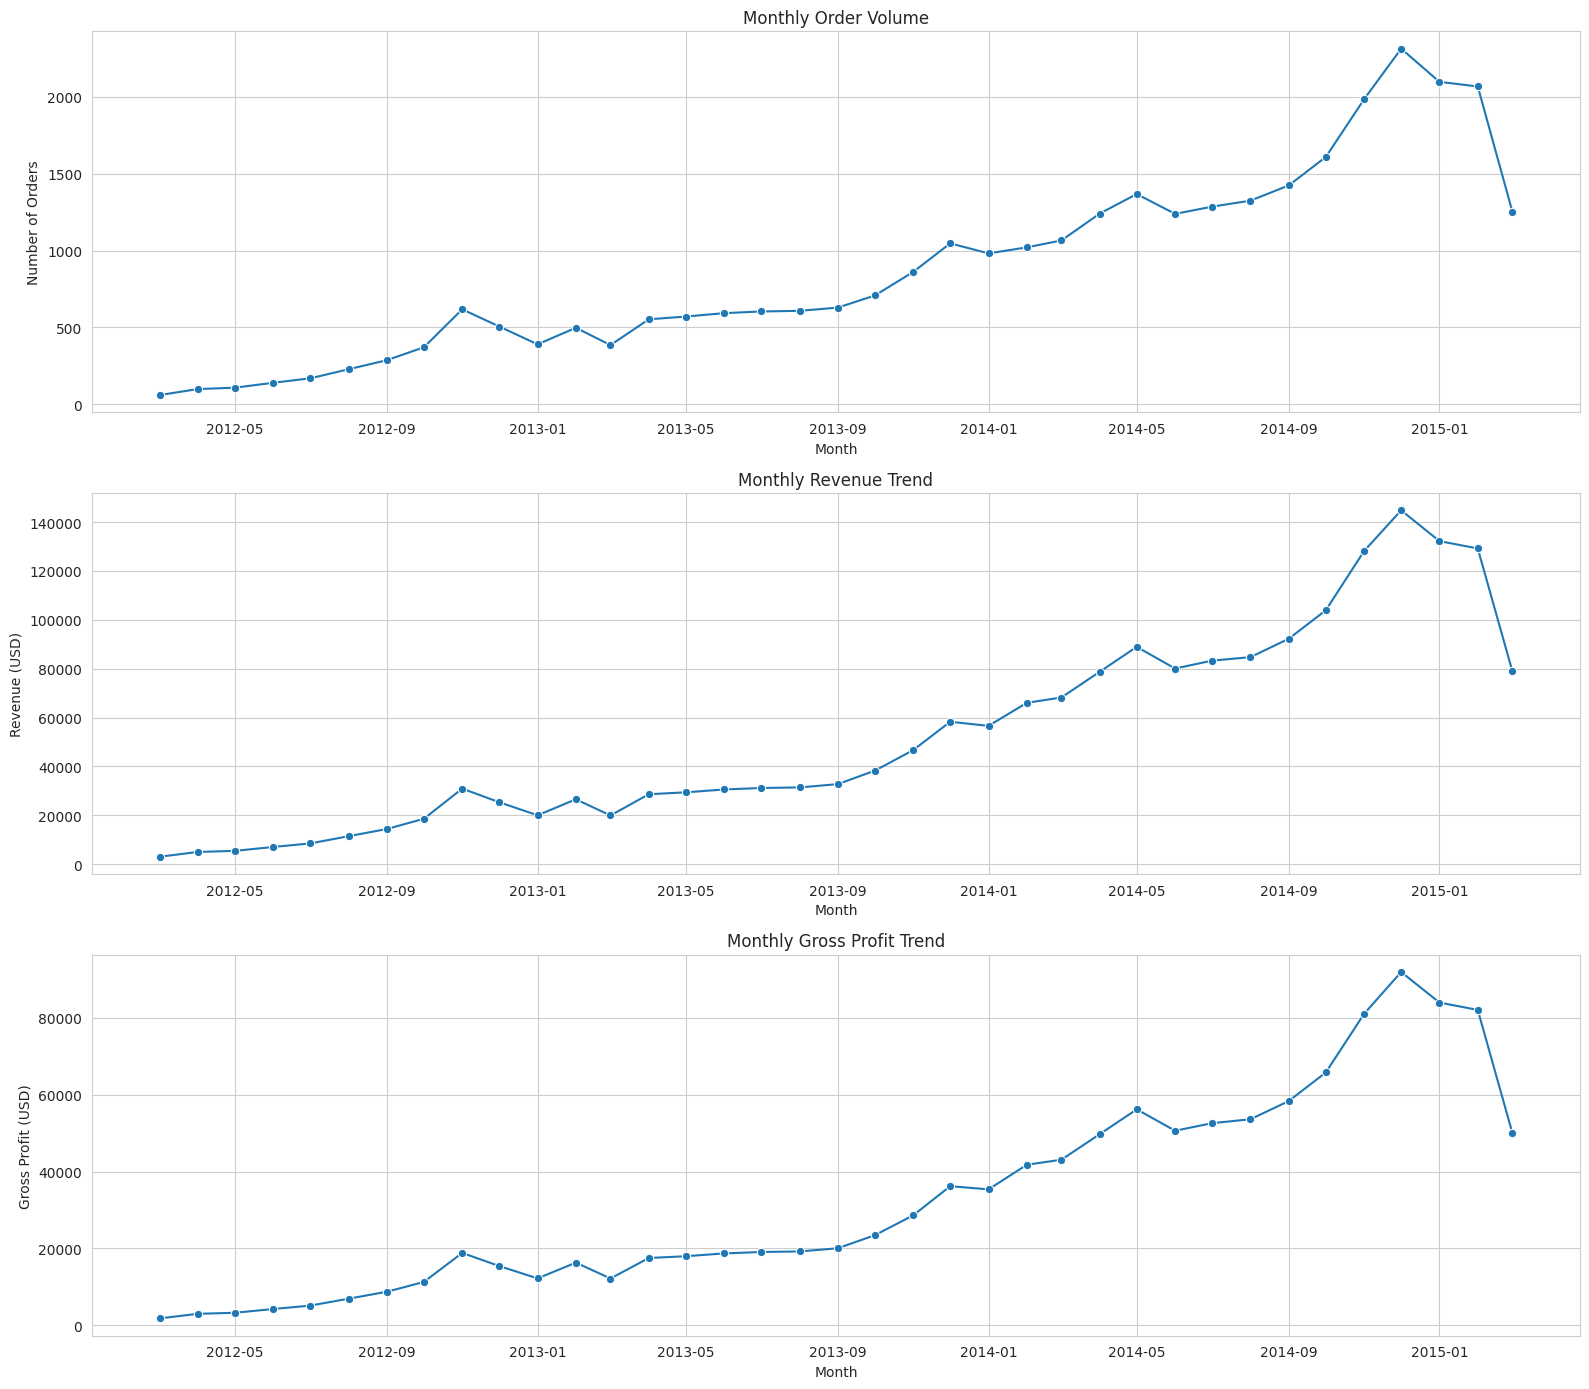

In [ ]:
# EDA 5.1.8: Monthly Business Performance Visualization

fig, axes = plt.subplots(3, 1, figsize=(16, 14))

# Monthly Orders
sns.lineplot(
    data=monthly_orders,
    x='created_at',
    y='Total_Orders',
    marker='o',
    ax=axes[0]
)
axes[0].set_title('Monthly Order Volume')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Number of Orders')

# Monthly Revenue
sns.lineplot(
    data=monthly_orders,
    x='created_at',
    y='Total_Revenue',
    marker='o',
    ax=axes[1]
)
axes[1].set_title('Monthly Revenue Trend')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Revenue (USD)')

# Monthly Gross Profit
sns.lineplot(
    data=monthly_orders,
    x='created_at',
    y='Total_Gross_Profit',
    marker='o',
    ax=axes[2]
)
axes[2].set_title('Monthly Gross Profit Trend')
axes[2].set_xlabel('Month')
axes[2].set_ylabel('Gross Profit (USD)')

plt.tight_layout()
plt.show()

### EDA 5.1.9 – Average Order Value (AOV) Analysis

**Business Question:**
What is the average order value, and how does it change month over month?

**Objective:**
Calculate overall and monthly AOV to evaluate customer spending patterns and identify changes in order value.

In [ ]:
# EDA 5.1.9: Average Order Value Analysis

overall_aov = orders['price_usd'].mean()

monthly_aov = (
    orders.set_index('created_at')
    .resample('MS')
    .agg(
        Total_Revenue=('price_usd', 'sum'),
        Total_Orders=('order_id', 'count')
    )
    .reset_index()
)

monthly_aov['AOV'] = (
    monthly_aov['Total_Revenue'] /
    monthly_aov['Total_Orders']
)

print(f"Overall Average Order Value: ${overall_aov:.2f}")

monthly_aov.head()

Overall Average Order Value: $59.99


,created_at,Total_Revenue,Total_Orders,AOV
0,2012-03-01,2999.40,60,49.99
1,2012-04-01,4949.01,99,49.99
2,2012-05-01,5398.92,108,49.99
3,2012-06-01,6998.60,140,49.99
4,2012-07-01,8448.31,169,49.99


### EDA 5.1.10 – Monthly AOV Trend Analysis

**Business Question:**
How does average order value fluctuate across months, and are there periods of increasing or declining customer spending?

**Objective:**
Visualize monthly AOV to identify customer spending trends and opportunities to improve revenue per order.

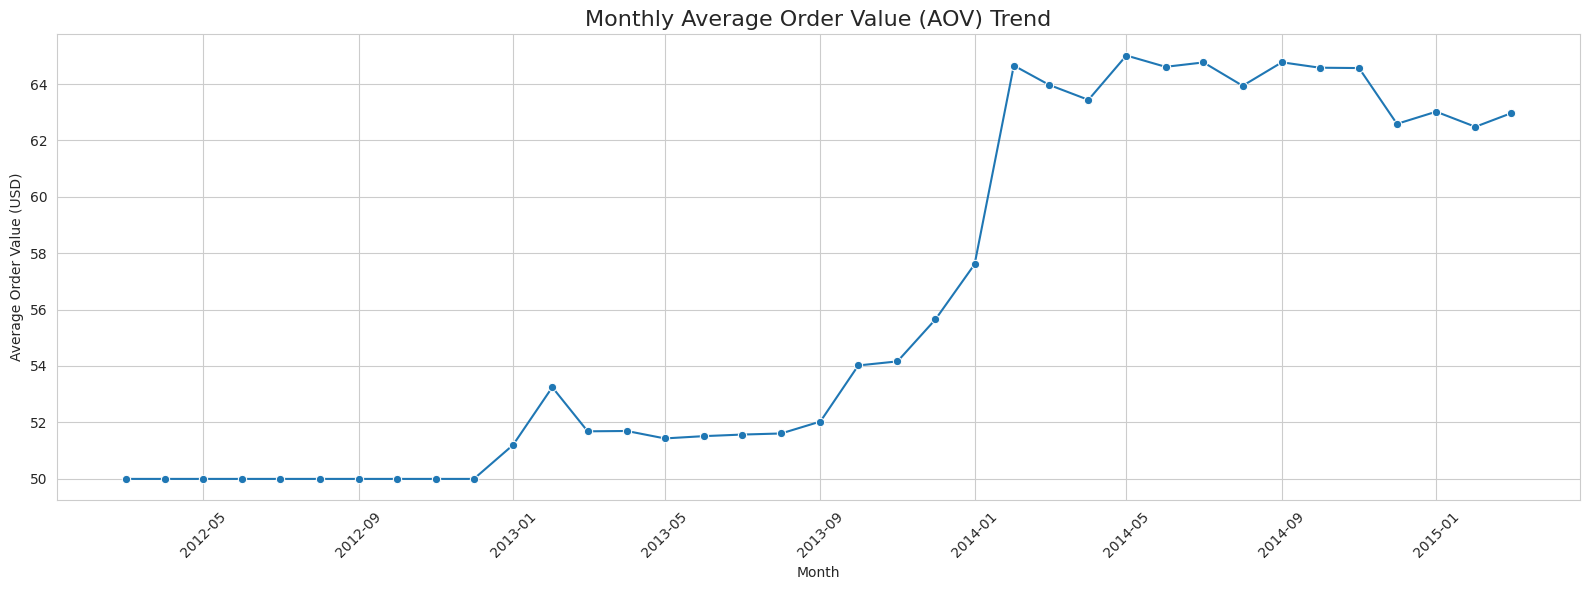

In [ ]:
# EDA 5.1.10: Monthly AOV Trend Visualization

plt.figure(figsize=(16, 6))

sns.lineplot(
    data=monthly_aov,
    x='created_at',
    y='AOV',
    marker='o'
)

plt.title('Monthly Average Order Value (AOV) Trend',
          fontsize=16)

plt.xlabel('Month')
plt.ylabel('Average Order Value (USD)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### EDA 5.1.11 – Month-over-Month Revenue Growth Analysis

**Business Question:**
How much does revenue increase or decrease compared with the previous month?

**Objective:**
Calculate monthly revenue growth percentages to evaluate business momentum and identify significant revenue fluctuations.

In [ ]:
# EDA 5.1.11: Month-over-Month Revenue Growth

monthly_orders['Previous_Month_Revenue'] = (
    monthly_orders['Total_Revenue'].shift(1)
)

monthly_orders['MoM_Revenue_Growth_%'] = (
    (monthly_orders['Total_Revenue'] -
     monthly_orders['Previous_Month_Revenue']) /
    monthly_orders['Previous_Month_Revenue']
) * 100

monthly_orders[
    ['created_at', 'Total_Revenue',
     'Previous_Month_Revenue', 'MoM_Revenue_Growth_%']
].round(2).head(12)

,created_at,Total_Revenue,Previous_Month_Revenue,MoM_Revenue_Growth_%
0,2012-03-01,2999.40,NaN,NaN
1,2012-04-01,4949.01,2999.40,65.00
2,2012-05-01,5398.92,4949.01,9.09
3,2012-06-01,6998.60,5398.92,29.63
4,2012-07-01,8448.31,6998.60,20.71
5,2012-08-01,11397.72,8448.31,34.91
6,2012-09-01,14347.13,11397.72,25.88
7,2012-10-01,18546.29,14347.13,29.27
8,2012-11-01,30893.82,18546.29,66.58
9,2012-12-01,25294.94,30893.82,-18.12


### EDA 5.1.12 – Cumulative Revenue Analysis

**Business Question:**
How does cumulative revenue grow month after month throughout the analysis period?

**Objective:**
Calculate cumulative revenue and visualize the long-term revenue progression of the business.

In [ ]:
# EDA 5.1.12: Cumulative Revenue Analysis

monthly_orders['Cumulative_Revenue'] = (
    monthly_orders['Total_Revenue'].cumsum()
)

monthly_orders[
    ['created_at', 'Total_Revenue', 'Cumulative_Revenue']
].round(2).head(12)

,created_at,Total_Revenue,Cumulative_Revenue
0,2012-03-01,2999.40,2999.40
1,2012-04-01,4949.01,7948.41
2,2012-05-01,5398.92,13347.33
3,2012-06-01,6998.60,20345.93
4,2012-07-01,8448.31,28794.24
5,2012-08-01,11397.72,40191.96
6,2012-09-01,14347.13,54539.09
7,2012-10-01,18546.29,73085.38
8,2012-11-01,30893.82,103979.20
9,2012-12-01,25294.94,129274.14


### EDA 5.1.13 – Cumulative Revenue Trend Visualization

**Business Question:**
How has the company's cumulative revenue progressed throughout the analysis period?

**Objective:**
Visualize cumulative revenue over time to evaluate long-term business growth and identify changes in revenue accumulation.

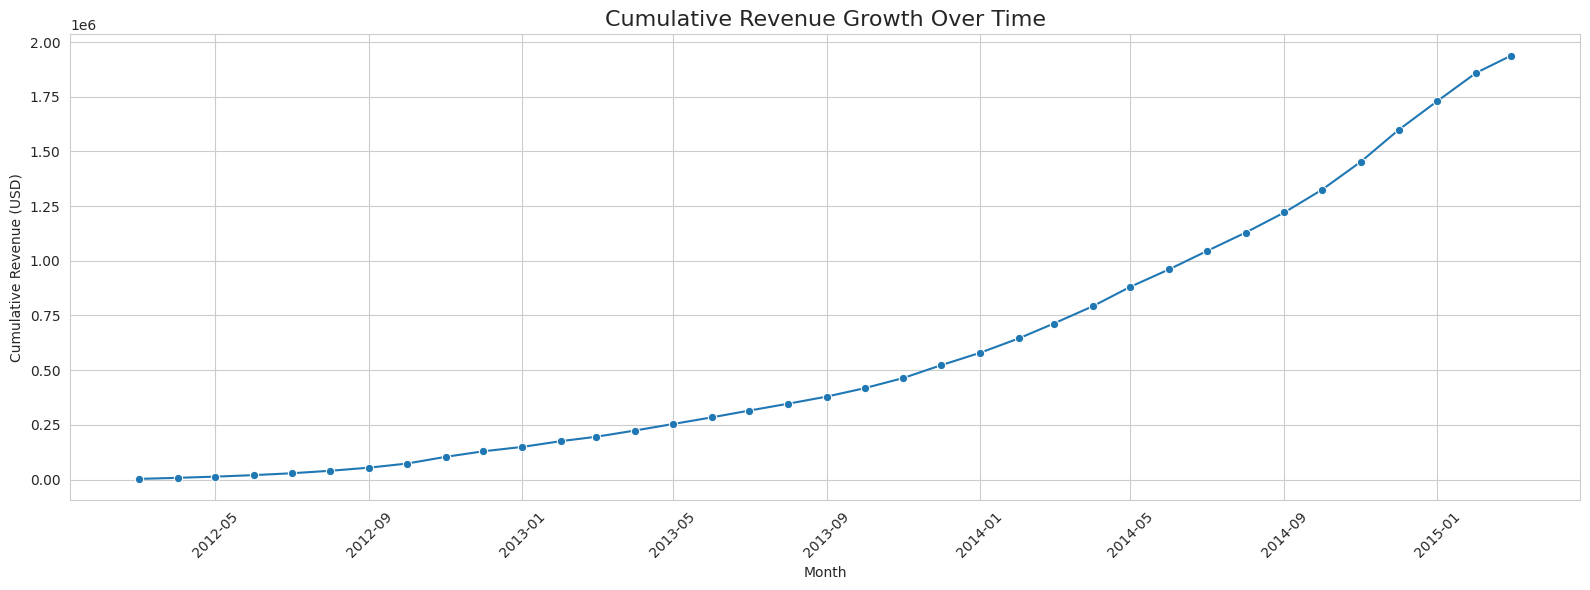

In [ ]:
# EDA 5.1.13: Cumulative Revenue Trend

plt.figure(figsize=(16, 6))

sns.lineplot(
    data=monthly_orders,
    x='created_at',
    y='Cumulative_Revenue',
    marker='o'
)

plt.title('Cumulative Revenue Growth Over Time', fontsize=16)
plt.xlabel('Month')
plt.ylabel('Cumulative Revenue (USD)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### EDA 5.1.14 – Monthly Gross Profit Margin Analysis

**Business Question:**

How does the company's gross profit margin fluctuate month over month, and are revenue growth and profitability moving together?

**Objective:**

Calculate monthly gross profit margins using total monthly gross profit divided by total monthly revenue. Identify periods of improving or declining profitability.

In [ ]:
# EDA 5.1.14: Monthly Gross Profit Margin Analysis

monthly_orders['Gross_Margin_%'] = (
    monthly_orders['Total_Gross_Profit'] /
    monthly_orders['Total_Revenue']
) * 100

monthly_orders[
    ['created_at', 'Total_Revenue',
     'Total_Gross_Profit', 'Gross_Margin_%']
].round(2).head(12)

,created_at,Total_Revenue,Total_Gross_Profit,Gross_Margin_%
0,2012-03-01,2999.40,1830.0,61.01
1,2012-04-01,4949.01,3019.5,61.01
2,2012-05-01,5398.92,3294.0,61.01
3,2012-06-01,6998.60,4270.0,61.01
4,2012-07-01,8448.31,5154.5,61.01
5,2012-08-01,11397.72,6954.0,61.01
6,2012-09-01,14347.13,8753.5,61.01
7,2012-10-01,18546.29,11315.5,61.01
8,2012-11-01,30893.82,18849.0,61.01
9,2012-12-01,25294.94,15433.0,61.01


### EDA 5.1.15 – Monthly Gross Profit Margin Visualization

**Business Question:**

During which months did the company achieve higher or lower gross profit margins?

**Objective:**

Visualize monthly gross profit margin to identify profitability fluctuations and periods requiring further investigation.

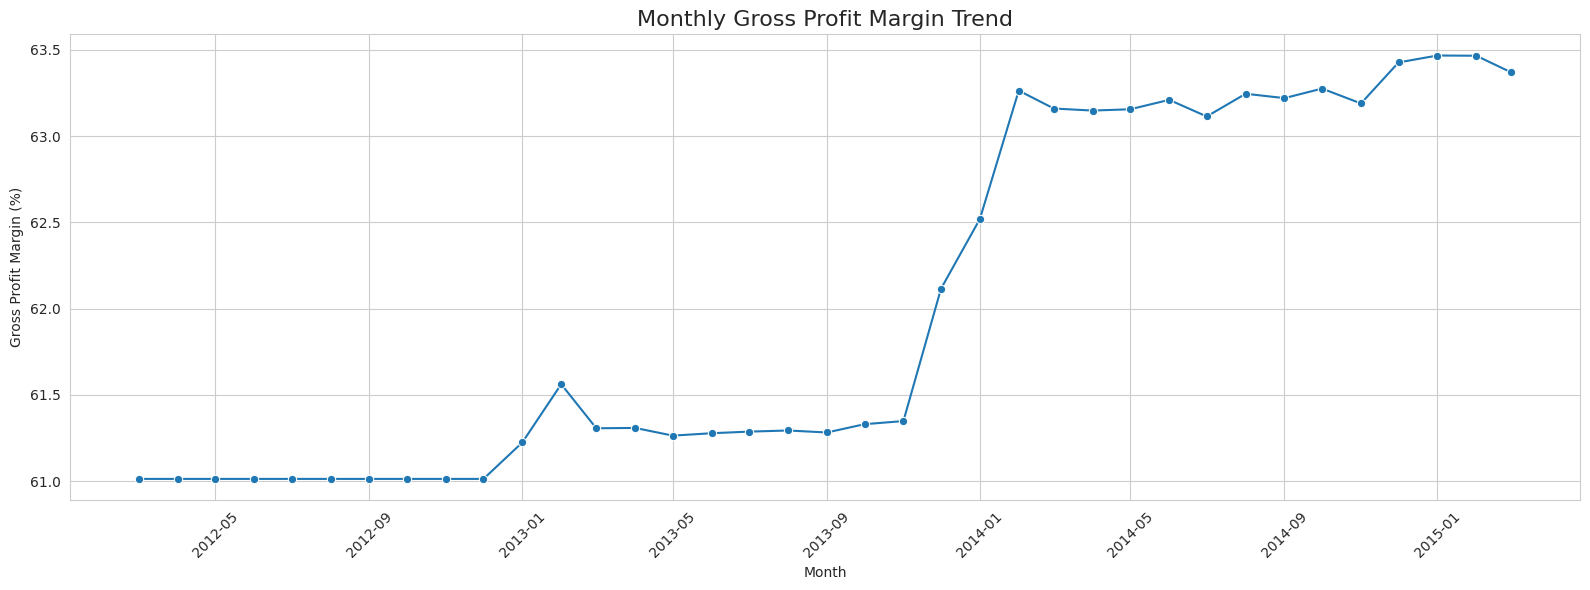

In [ ]:
# EDA 5.1.15: Monthly Gross Profit Margin Visualization

plt.figure(figsize=(16, 6))

sns.lineplot(
    data=monthly_orders,
    x='created_at',
    y='Gross_Margin_%',
    marker='o'
)

plt.title('Monthly Gross Profit Margin Trend', fontsize=16)
plt.xlabel('Month')
plt.ylabel('Gross Profit Margin (%)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### EDA 5.1.16 – Monthly Order Volume Growth Analysis

**Business Question:**

How does monthly order volume change compared with the previous month?

**Objective:**

Calculate Month-over-Month order growth to identify expansion, contraction and fluctuations in transaction volume.

In [ ]:
# EDA 5.1.16: Monthly Order Volume Growth

monthly_orders['Previous_Month_Orders'] = (
    monthly_orders['Total_Orders'].shift(1)
)

monthly_orders['MoM_Order_Growth_%'] = (
    (monthly_orders['Total_Orders'] -
     monthly_orders['Previous_Month_Orders']) /
    monthly_orders['Previous_Month_Orders']
) * 100

monthly_orders[
    ['created_at', 'Total_Orders',
     'Previous_Month_Orders', 'MoM_Order_Growth_%']
].round(2).head(12)

,created_at,Total_Orders,Previous_Month_Orders,MoM_Order_Growth_%
0,2012-03-01,60,NaN,NaN
1,2012-04-01,99,60.0,65.00
2,2012-05-01,108,99.0,9.09
3,2012-06-01,140,108.0,29.63
4,2012-07-01,169,140.0,20.71
5,2012-08-01,228,169.0,34.91
6,2012-09-01,287,228.0,25.88
7,2012-10-01,371,287.0,29.27
8,2012-11-01,618,371.0,66.58
9,2012-12-01,506,618.0,-18.12


### EDA 5.1.16 – Monthly Order Volume Growth Analysis

**Business Question:**

How does the number of orders change month over month, and which months experience the highest growth or decline?

**Objective:**

Measure monthly order growth to understand business expansion and transaction-volume fluctuations.

In [ ]:
# EDA 5.1.16: Monthly Order Volume Growth

monthly_orders['Previous_Month_Orders'] = (
    monthly_orders['Total_Orders'].shift(1)
)

monthly_orders['MoM_Order_Growth_%'] = (
    (monthly_orders['Total_Orders'] -
     monthly_orders['Previous_Month_Orders']) /
    monthly_orders['Previous_Month_Orders']
) * 100

monthly_orders[
    ['created_at', 'Total_Orders',
     'Previous_Month_Orders', 'MoM_Order_Growth_%']
].round(2).head(12)

,created_at,Total_Orders,Previous_Month_Orders,MoM_Order_Growth_%
0,2012-03-01,60,NaN,NaN
1,2012-04-01,99,60.0,65.00
2,2012-05-01,108,99.0,9.09
3,2012-06-01,140,108.0,29.63
4,2012-07-01,169,140.0,20.71
5,2012-08-01,228,169.0,34.91
6,2012-09-01,287,228.0,25.88
7,2012-10-01,371,287.0,29.27
8,2012-11-01,618,371.0,66.58
9,2012-12-01,506,618.0,-18.12


### EDA 5.1.17 – Weekday vs. Weekend Order Analysis

**Business Question:**

Do customers place more orders on weekdays or weekends? Which days generate the highest order volume and revenue?

**Objective:**

Analyze daily and weekday-versus-weekend order volume, revenue and average order value to identify purchasing patterns.

In [ ]:
# EDA 5.1.17: Weekday vs Weekend Analysis

orders['Day_Name'] = orders['created_at'].dt.day_name()

orders['Day_Type'] = np.where(
    orders['created_at'].dt.dayofweek >= 5,
    'Weekend',
    'Weekday'
)

daily_performance = (
    orders.groupby('Day_Name')
    .agg(
        Total_Orders=('order_id', 'count'),
        Total_Revenue=('price_usd', 'sum'),
        Total_Gross_Profit=('gross_profit', 'sum')
    )
    .reindex([
        'Monday', 'Tuesday', 'Wednesday',
        'Thursday', 'Friday', 'Saturday', 'Sunday'
    ])
)

daily_performance['AOV'] = (
    daily_performance['Total_Revenue'] /
    daily_performance['Total_Orders']
)

daily_performance.round(2)

,Total_Orders,Total_Revenue,Total_Gross_Profit,AOV
Day_Name,,,,
Monday,5662,339922.02,213247.0,60.04
Tuesday,5320,321095.80,201482.0,60.36
Wednesday,5499,328326.21,205993.5,59.71
Thursday,5414,325364.67,204118.5,60.10
Friday,5571,332927.37,208592.5,59.76
Saturday,2309,138053.34,86702.0,59.79
Sunday,2538,152820.34,96004.0,60.21


## 5.2 – Order Items Dataset: Exploratory Data Analysis

### EDA 5.2.1 – Order Items Dataset: Business Understanding

**Business Context:**

The company wants to understand product-level purchasing behavior, sales contribution and profitability. Since one order can contain multiple items, order-level analysis alone cannot explain individual product performance.

**Business Question:**

Which products contribute most to sales revenue and gross profit, how many items are purchased, and what is the contribution of primary versus additional products?

**Objective:**

Analyze item-level transactions to evaluate product sales volume, revenue, cost, profitability and purchasing patterns.

In [ ]:
import pandas as pd
import numpy as np

# Load all six datasets
orders = pd.read_csv('/content/orders.csv')
order_items = pd.read_csv('/content/order_items.csv')
order_item_refunds = pd.read_csv('/content/order_item_refunds.csv')
products = pd.read_csv('/content/products.csv')
website_pageviews = pd.read_csv('/content/website_pageviews (1).csv')
website_sessions = pd.read_csv('/content/website_sessions (1).csv')

print("All six datasets loaded successfully!")

All six datasets loaded successfully!


In [ ]:
datasets = {
    'Orders': orders,
    'Order Items': order_items,
    'Order Item Refunds': order_item_refunds,
    'Products': products,
    'Website Pageviews': website_pageviews,
    'Website Sessions': website_sessions
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")

Orders: 32,313 rows × 8 columns
Order Items: 40,025 rows × 7 columns
Order Item Refunds: 1,731 rows × 5 columns
Products: 4 rows × 3 columns
Website Pageviews: 1,188,124 rows × 4 columns
Website Sessions: 472,871 rows × 9 columns


In [ ]:
print("Dataset Shape:", order_items.shape)

print("\nColumn Names:")
print(order_items.columns.tolist())

print("\nDataset Information:")
order_items.info()

Dataset Shape: (40025, 7)

Column Names:
['order_item_id', 'created_at', 'order_id', 'product_id', 'is_primary_item', 'price_usd', 'cogs_usd']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40025 entries, 0 to 40024
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_item_id    40025 non-null  int64  
 1   created_at       40025 non-null  object 
 2   order_id         40025 non-null  int64  
 3   product_id       40025 non-null  int64  
 4   is_primary_item  40025 non-null  int64  
 5   price_usd        40025 non-null  float64
 6   cogs_usd         40025 non-null  float64
dtypes: float64(2), int64(4), object(1)
memory usage: 2.1+ MB


In [ ]:
order_items.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
order_item_id,40025.0,20013.00,11554.37,1.00,10007.00,20013.00,30019.00,40025.00
order_id,40025.0,17121.96,9053.77,1.00,9871.00,17490.00,24818.00,32313.00
product_id,40025.0,1.77,1.09,1.00,1.00,1.00,2.00,4.00
is_primary_item,40025.0,0.81,0.39,0.00,1.00,1.00,1.00,1.00
price_usd,40025.0,48.43,8.01,29.99,49.99,49.99,49.99,59.99
cogs_usd,40025.0,18.05,3.86,9.49,19.49,19.49,19.49,22.49


### EDA 5.2.3 – Product-Level Revenue and Profitability

**Business Question:**

How much revenue, cost and gross profit does each product generate, and which products contribute most to overall profitability?

**Objective:**

Calculate item-level revenue, COGS, gross profit and gross margin to evaluate product-level financial performance.

In [ ]:
# EDA 5.2.3: Item-Level Profitability

order_items['gross_profit'] = (
    order_items['price_usd'] - order_items['cogs_usd']
)

order_items['gross_margin_pct'] = (
    order_items['gross_profit'] /
    order_items['price_usd']
) * 100

print("Total Item Revenue:",
      round(order_items['price_usd'].sum(), 2))

print("Total Item COGS:",
      round(order_items['cogs_usd'].sum(), 2))

print("Total Item Gross Profit:",
      round(order_items['gross_profit'].sum(), 2))

print("Overall Item Gross Margin:",
      round(
          order_items['gross_profit'].sum() /
          order_items['price_usd'].sum() * 100, 2
      ), "%")

Total Item Revenue: 1938509.75
Total Item COGS: 722370.25
Total Item Gross Profit: 1216139.5
Overall Item Gross Margin: 62.74 %


### EDA 5.2.4 – Primary vs. Additional Product Analysis

**Business Question:**

What proportion of order items are primary products versus additional products, and how do their revenue and profitability compare?

**Objective:**

Compare item counts, revenue, COGS and gross profit based on the primary-item indicator.

In [ ]:
# EDA 5.2.4: Primary vs Additional Product Analysis

primary_analysis = (
    order_items.groupby('is_primary_item')
    .agg(
        Total_Items=('order_item_id', 'count'),
        Total_Revenue=('price_usd', 'sum'),
        Total_COGS=('cogs_usd', 'sum'),
        Total_Gross_Profit=('gross_profit', 'sum')
    )
    .reset_index()
)

primary_analysis['Gross_Margin_%'] = (
    primary_analysis['Total_Gross_Profit'] /
    primary_analysis['Total_Revenue']
) * 100

primary_analysis['Item_Share_%'] = (
    primary_analysis['Total_Items'] /
    len(order_items)
) * 100

primary_analysis.round(2)

,is_primary_item,Total_Items,Total_Revenue,Total_COGS,Total_Gross_Profit,Gross_Margin_%,Item_Share_%
0,0,7712,299044.88,99330.88,199714.0,66.78,19.27
1,1,32313,1639464.87,623039.37,1016425.5,62.00,80.73


### EDA 5.2.5 – Product Quantity and Sales Contribution Analysis

**Business Question:**

How many primary and additional products are sold, and what proportion of total item revenue does each contribute?

**Objective:**

Measure item volume and revenue contribution to understand the role of additional products in overall sales performance.

In [ ]:
# EDA 5.2.5: Product Quantity and Revenue Contribution

primary_analysis['Revenue_Share_%'] = (
    primary_analysis['Total_Revenue'] /
    primary_analysis['Total_Revenue'].sum()
) * 100

primary_analysis[
    ['is_primary_item', 'Total_Items',
     'Item_Share_%', 'Total_Revenue', 'Revenue_Share_%']
].round(2)

,is_primary_item,Total_Items,Item_Share_%,Total_Revenue,Revenue_Share_%
0,0,7712,19.27,299044.88,15.43
1,1,32313,80.73,1639464.87,84.57


### EDA 5.2.6 – Product-Level Sales Performance

**Business Question:**

Which products contribute the most to total revenue, sales volume and gross profit?

**Objective:**

Aggregate order-item transactions by product and evaluate product-level sales volume, revenue, COGS, gross profit and gross margin.

In [ ]:
# EDA 5.2.6: Product-Level Sales Performance

product_performance = (
    order_items.groupby('product_id')
    .agg(
        Total_Items_Sold=('order_item_id', 'count'),
        Total_Orders=('order_id', 'nunique'),
        Total_Revenue=('price_usd', 'sum'),
        Total_COGS=('cogs_usd', 'sum'),
        Total_Gross_Profit=('gross_profit', 'sum')
    )
    .reset_index()
)

product_performance['Gross_Margin_%'] = (
    product_performance['Total_Gross_Profit'] /
    product_performance['Total_Revenue']
) * 100

product_performance['Revenue_Share_%'] = (
    product_performance['Total_Revenue'] /
    product_performance['Total_Revenue'].sum()
) * 100

product_performance = product_performance.sort_values(
    'Total_Revenue', ascending=False
)

product_performance.round(2)

,product_id,Total_Items_Sold,Total_Orders,Total_Revenue,Total_COGS,Total_Gross_Profit,Gross_Margin_%,Revenue_Share_%
0,1,24226,24226,1211057.74,472164.74,738893.0,61.01,62.47
1,2,5796,5796,347702.04,130352.04,217350.0,62.51,17.94
2,3,4985,4985,229260.15,72232.65,157027.5,68.49,11.83
3,4,5018,5018,150489.82,47620.82,102869.0,68.36,7.76


### EDA 5.2.7 – Product Revenue and Profitability Visualization

**Business Question:**

Which products generate the highest revenue and gross profit, and how do their financial contributions compare?

**Objective:**

Create comparative visualizations of product revenue and gross profit to identify top-performing products and profitability differences.

In [ ]:
# EDA 5.2.7: Product Revenue and Profitability Visualization

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Revenue comparison
sns.barplot(
    data=product_performance,
    x='product_id',
    y='Total_Revenue',
    ax=axes[0]
)

axes[0].set_title('Revenue by Product')
axes[0].set_xlabel('Product ID')
axes[0].set_ylabel('Revenue (USD)')

# Gross profit comparison
sns.barplot(
    data=product_performance,
    x='product_id',
    y='Total_Gross_Profit',
    ax=axes[1]
)

axes[1].set_title('Gross Profit by Product')
axes[1].set_xlabel('Product ID')
axes[1].set_ylabel('Gross Profit (USD)')

plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Visualization libraries imported successfully!")

Visualization libraries imported successfully!


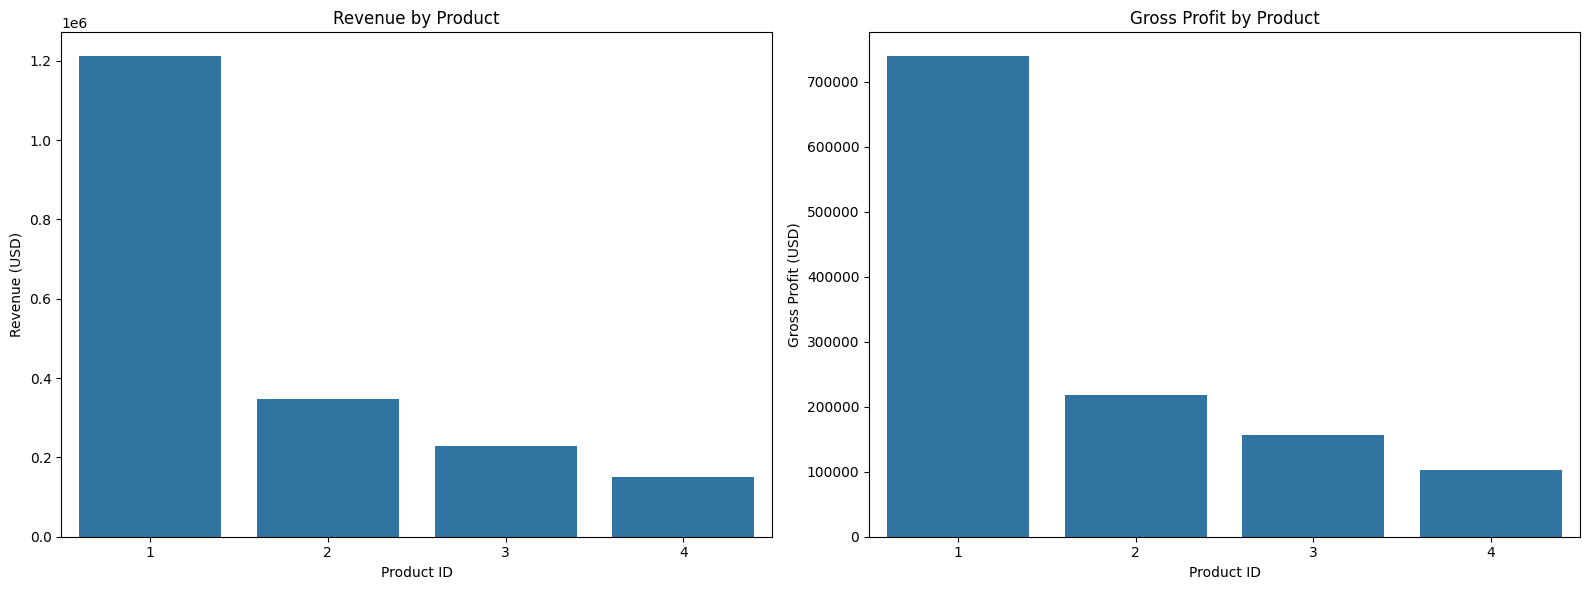

In [ ]:
# EDA 5.2.7: Product Revenue and Profitability Visualization

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Revenue comparison
sns.barplot(
    data=product_performance,
    x='product_id',
    y='Total_Revenue',
    ax=axes[0]
)

axes[0].set_title('Revenue by Product')
axes[0].set_xlabel('Product ID')
axes[0].set_ylabel('Revenue (USD)')

# Gross profit comparison
sns.barplot(
    data=product_performance,
    x='product_id',
    y='Total_Gross_Profit',
    ax=axes[1]
)

axes[1].set_title('Gross Profit by Product')
axes[1].set_xlabel('Product ID')
axes[1].set_ylabel('Gross Profit (USD)')

plt.tight_layout()
plt.show()

### EDA 5.2.8 – Order Item Refund Analysis

**Business Question:**

How many order items are refunded, what is the refund amount, and what is the refund rate?

**Objective:**

Calculate refund volume, refund value, and refund rate to evaluate the financial impact of product returns.

In [ ]:
# EDA 5.2.8: Order Item Refund Analysis

total_items = order_items['order_item_id'].nunique()
total_refunded_items = order_item_refunds['order_item_id'].nunique()

total_refund_amount = order_item_refunds['refund_amount_usd'].sum()

refund_rate = (
    total_refunded_items / total_items
) * 100

print("Total Order Items:", total_items)
print("Total Refunded Items:", total_refunded_items)
print("Total Refund Amount ($):", round(total_refund_amount, 2))
print("Overall Refund Rate (%):", round(refund_rate, 2))

Total Order Items: 40025
Total Refunded Items: 1731
Total Refund Amount ($): 85338.69
Overall Refund Rate (%): 4.32


### EDA 5.2.9 – Product-Wise Refund Analysis

**Business Question:**

Which products have the highest refund rates and refund amounts?

**Objective:**

Compare product-level sales volume, refunded items, refund rates and refund amounts to identify products requiring further investigation.

In [ ]:
# EDA 5.2.9: Product-Wise Refund Analysis

product_refunds = (
    order_items.groupby('product_id')
    .agg(Total_Items=('order_item_id', 'nunique'))
    .reset_index()
)

refund_counts = (
    order_item_refunds.merge(
        order_items[['order_item_id', 'product_id']],
        on='order_item_id',
        how='left'
    )
    .groupby('product_id')
    .agg(
        Refunded_Items=('order_item_id', 'nunique'),
        Total_Refund_Amount=('refund_amount_usd', 'sum')
    )
    .reset_index()
)

product_refunds = product_refunds.merge(
    refund_counts,
    on='product_id',
    how='left'
)

product_refunds[['Refunded_Items', 'Total_Refund_Amount']] = (
    product_refunds[['Refunded_Items', 'Total_Refund_Amount']]
    .fillna(0)
)

product_refunds['Refund_Rate_%'] = (
    product_refunds['Refunded_Items'] /
    product_refunds['Total_Items']
) * 100

product_refunds = product_refunds.merge(
    products[['product_id', 'product_name']],
    on='product_id',
    how='left'
)

product_refunds.sort_values(
    'Refund_Rate_%',
    ascending=False
).round(2)

,product_id,Total_Items,Refunded_Items,Total_Refund_Amount,Refund_Rate_%,product_name
2,3,4985,301,13842.99,6.04,The Birthday Sugar Panda
0,1,24226,1237,61837.63,5.11,The Original Mr. Fuzzy
1,2,5796,129,7738.71,2.23,The Forever Love Bear
3,4,5018,64,1919.36,1.28,The Hudson River Mini bear


### EDA 5.2.10 – Customer Order Frequency Analysis

**Business Question:**

How many customers are one-time buyers versus repeat buyers, and how do their purchasing patterns differ?

**Objective:**

Segment customers based on order frequency and compare customer count, total orders, revenue and average revenue per customer.

In [ ]:
# EDA 5.2.10: Customer Order Frequency Analysis

customer_orders = (
    orders.groupby('user_id')
    .agg(
        Total_Orders=('order_id', 'nunique'),
        Total_Revenue=('price_usd', 'sum')
    )
    .reset_index()
)

customer_orders['Customer_Segment'] = np.where(
    customer_orders['Total_Orders'] == 1,
    'One-Time Buyer',
    'Repeat Buyer'
)

customer_segments = (
    customer_orders.groupby('Customer_Segment')
    .agg(
        Total_Customers=('user_id', 'nunique'),
        Total_Orders=('Total_Orders', 'sum'),
        Total_Revenue=('Total_Revenue', 'sum')
    )
    .reset_index()
)

customer_segments['Revenue_Per_Customer'] = (
    customer_segments['Total_Revenue'] /
    customer_segments['Total_Customers']
)

customer_segments.round(2)

,Customer_Segment,Total_Customers,Total_Orders,Total_Revenue,Revenue_Per_Customer
0,One-Time Buyer,31105,31105,1864153.31,59.93
1,Repeat Buyer,591,1208,74356.44,125.81


### EDA 5.2.11 – Repeat Purchase Rate Analysis

**Business Question:**

What percentage of customers make repeat purchases, and what proportion of total revenue is generated by repeat customers?

**Objective:**

Calculate the repeat purchase rate, customer segment contribution and revenue contribution to evaluate customer retention performance.

In [ ]:
# EDA 5.2.11: Repeat Purchase Rate Analysis

total_customers = customer_orders['user_id'].nunique()

repeat_customers = customer_orders[
    customer_orders['Total_Orders'] > 1
]['user_id'].nunique()

repeat_purchase_rate = (
    repeat_customers / total_customers
) * 100

repeat_revenue_share = (
    customer_orders.loc[
        customer_orders['Customer_Segment'] == 'Repeat Buyer',
        'Total_Revenue'
    ].sum() / customer_orders['Total_Revenue'].sum()
) * 100

print(f"Total Customers: {total_customers:,}")
print(f"Repeat Customers: {repeat_customers:,}")
print(f"Repeat Purchase Rate: {repeat_purchase_rate:.2f}%")
print(f"Repeat Customer Revenue Share: {repeat_revenue_share:.2f}%")

Total Customers: 31,696
Repeat Customers: 591
Repeat Purchase Rate: 1.86%
Repeat Customer Revenue Share: 3.84%


### EDA 5.2.12 – Customer Revenue Contribution Analysis

**Business Question:**

What percentage of total revenue is generated by the top 10% of customers, and how concentrated is revenue among high-value customers?

**Objective:**

Rank customers by revenue, calculate cumulative revenue contribution and identify high-value customer segments using Pareto analysis.

In [ ]:
# EDA 5.2.12: Customer Revenue Contribution Analysis

customer_revenue = (
    orders.groupby('user_id')
    .agg(Total_Revenue=('price_usd', 'sum'))
    .reset_index()
    .sort_values('Total_Revenue', ascending=False)
)

customer_revenue['Revenue_Share_%'] = (
    customer_revenue['Total_Revenue'] /
    customer_revenue['Total_Revenue'].sum()
) * 100

customer_revenue['Cumulative_Revenue_%'] = (
    customer_revenue['Revenue_Share_%'].cumsum()
)

customer_revenue['Customer_Rank'] = (
    customer_revenue['Total_Revenue'].rank(
        method='first',
        ascending=False
    ).astype(int)
)

top_10_percent_count = int(np.ceil(len(customer_revenue) * 0.10))

top_10_percent_revenue_share = (
    customer_revenue.head(top_10_percent_count)['Total_Revenue'].sum()
    / customer_revenue['Total_Revenue'].sum()
) * 100

print(f"Total Customers: {len(customer_revenue):,}")
print(f"Top 10% Customer Count: {top_10_percent_count:,}")
print(f"Top 10% Revenue Contribution: {top_10_percent_revenue_share:.2f}%")

customer_revenue.head(10).round(2)

Total Customers: 31,696
Top 10% Customer Count: 3,170
Top 10% Revenue Contribution: 17.40%


,user_id,Total_Revenue,Revenue_Share_%,Cumulative_Revenue_%,Customer_Rank
26808,341972,251.94,0.01,0.01,1
25167,324814,245.95,0.01,0.03,2
11722,172266,237.95,0.01,0.04,3
20506,275098,235.95,0.01,0.05,4
9314,142410,219.96,0.01,0.06,5
21062,281298,219.96,0.01,0.07,6
24501,317773,215.96,0.01,0.08,7
26264,336150,209.95,0.01,0.09,8
15628,218722,205.96,0.01,0.11,9
10652,158790,205.96,0.01,0.12,10


### EDA 5.2.12 – Customer Revenue Contribution Analysis

**Business Question:**

What percentage of total revenue is generated by the top 10% of customers, and how concentrated is revenue among high-value customers?

**Objective:**

Rank customers by revenue, calculate cumulative revenue contribution and identify high-value customer segments using Pareto analysis.

In [ ]:
# EDA 5.2.12: Customer Revenue Contribution Analysis

customer_revenue = (
    orders.groupby('user_id')
    .agg(Total_Revenue=('price_usd', 'sum'))
    .reset_index()
    .sort_values('Total_Revenue', ascending=False)
)

customer_revenue['Revenue_Share_%'] = (
    customer_revenue['Total_Revenue'] /
    customer_revenue['Total_Revenue'].sum()
) * 100

customer_revenue['Cumulative_Revenue_%'] = (
    customer_revenue['Revenue_Share_%'].cumsum()
)

customer_revenue['Customer_Rank'] = (
    customer_revenue['Total_Revenue']
    .rank(method='first', ascending=False)
    .astype(int)
)

top_10_percent_count = int(np.ceil(len(customer_revenue) * 0.10))

top_10_percent_revenue_share = (
    customer_revenue.head(top_10_percent_count)['Total_Revenue'].sum()
    / customer_revenue['Total_Revenue'].sum()
) * 100

print(f"Total Customers: {len(customer_revenue):,}")
print(f"Top 10% Customer Count: {top_10_percent_count:,}")
print(f"Top 10% Revenue Contribution: {top_10_percent_revenue_share:.2f}%")

customer_revenue.head(10).round(2)

Total Customers: 31,696
Top 10% Customer Count: 3,170
Top 10% Revenue Contribution: 17.40%


,user_id,Total_Revenue,Revenue_Share_%,Cumulative_Revenue_%,Customer_Rank
26808,341972,251.94,0.01,0.01,1
25167,324814,245.95,0.01,0.03,2
11722,172266,237.95,0.01,0.04,3
20506,275098,235.95,0.01,0.05,4
9314,142410,219.96,0.01,0.06,5
21062,281298,219.96,0.01,0.07,6
24501,317773,215.96,0.01,0.08,7
26264,336150,209.95,0.01,0.09,8
15628,218722,205.96,0.01,0.11,9
10652,158790,205.96,0.01,0.12,10


### EDA 5.2.13 – Product Revenue Concentration Analysis

**Business Question:**

Do a small number of products generate most of the company's revenue?

**Objective:**

Measure each product's revenue contribution and cumulative revenue share to identify the products driving overall business performance.

In [ ]:
# EDA 5.2.13: Product Revenue Concentration Analysis

product_revenue = (
    order_items.groupby('product_id')
    .agg(
        Total_Revenue=('price_usd', 'sum'),
        Total_Items_Sold=('order_item_id', 'nunique')
    )
    .reset_index()
    .sort_values('Total_Revenue', ascending=False)
)

product_revenue['Revenue_Share_%'] = (
    product_revenue['Total_Revenue'] /
    product_revenue['Total_Revenue'].sum()
) * 100

product_revenue['Cumulative_Revenue_%'] = (
    product_revenue['Revenue_Share_%'].cumsum()
)

product_revenue = product_revenue.merge(
    products[['product_id', 'product_name']],
    on='product_id',
    how='left'
)

product_revenue = product_revenue[
    [
        'product_id',
        'product_name',
        'Total_Items_Sold',
        'Total_Revenue',
        'Revenue_Share_%',
        'Cumulative_Revenue_%'
    ]
]

print("Product Revenue Concentration:")
display(product_revenue.round(2))

Product Revenue Concentration:


,product_id,product_name,Total_Items_Sold,Total_Revenue,Revenue_Share_%,Cumulative_Revenue_%
0,1,The Original Mr. Fuzzy,24226,1211057.74,62.47,62.47
1,2,The Forever Love Bear,5796,347702.04,17.94,80.41
2,3,The Birthday Sugar Panda,4985,229260.15,11.83,92.24
3,4,The Hudson River Mini bear,5018,150489.82,7.76,100.00


5.3 Refunds Dataset – Exploratory Data Analysis
The objective of this section is to understand refund patterns, quantify revenue returned to customers and identify potential product-quality or customer-experience issues.

### EDA 5.3.1 – Overall Refund Performance

**Business Question:**

How much revenue is being refunded, how many items are refunded, and what is the overall refund rate?

**Objective:**

Measure refund volume and financial impact against total items sold.

In [ ]:
# EDA 5.3.1: Overall Refund Performance

total_items_sold = order_items['order_item_id'].nunique()

total_refunded_items = (
    order_item_refunds['order_item_id'].nunique()
)

total_refund_transactions = (
    order_item_refunds['order_item_refund_id'].nunique()
)

total_refund_amount = (
    order_item_refunds['refund_amount_usd'].sum()
)

overall_refund_rate = (
    total_refunded_items / total_items_sold
) * 100

average_refund_amount = (
    total_refund_amount / total_refund_transactions
    if total_refund_transactions > 0 else 0
)

print(f"Total Items Sold: {total_items_sold:,}")
print(f"Total Refunded Items: {total_refunded_items:,}")
print(f"Total Refund Transactions: {total_refund_transactions:,}")
print(f"Total Refund Amount: ${total_refund_amount:,.2f}")
print(f"Overall Item Refund Rate: {overall_refund_rate:.2f}%")
print(f"Average Refund Transaction Amount: ${average_refund_amount:,.2f}")

Total Items Sold: 40,025
Total Refunded Items: 1,731
Total Refund Transactions: 1,731
Total Refund Amount: $85,338.69
Overall Item Refund Rate: 4.32%
Average Refund Transaction Amount: $49.30


### EDA 5.3.2 – Product-Wise Refund Rate Analysis

**Business Question:**

Which products have the highest refund rates, and which products contribute most to total refunded revenue?

**Objective:**

Compare product-level refund rates and refund amounts to identify products that may require quality or customer-experience improvements.

In [ ]:
# EDA 5.3.2: Product-Wise Refund Rate Analysis

product_refund_analysis = (
    order_items.groupby('product_id')
    .agg(
        Total_Items_Sold=('order_item_id', 'nunique')
    )
    .reset_index()
)

refund_details = (
    order_item_refunds
    .merge(
        order_items[['order_item_id', 'product_id']],
        on='order_item_id',
        how='left'
    )
    .groupby('product_id')
    .agg(
        Refunded_Items=('order_item_id', 'nunique'),
        Total_Refund_Amount=('refund_amount_usd', 'sum')
    )
    .reset_index()
)

product_refund_analysis = product_refund_analysis.merge(
    refund_details,
    on='product_id',
    how='left'
)

product_refund_analysis[
    ['Refunded_Items', 'Total_Refund_Amount']
] = product_refund_analysis[
    ['Refunded_Items', 'Total_Refund_Amount']
].fillna(0)

product_refund_analysis['Refund_Rate_%'] = (
    product_refund_analysis['Refunded_Items'] /
    product_refund_analysis['Total_Items_Sold']
) * 100

product_refund_analysis = product_refund_analysis.merge(
    products[['product_id', 'product_name']],
    on='product_id',
    how='left'
)

product_refund_analysis = product_refund_analysis.sort_values(
    'Refund_Rate_%',
    ascending=False
)

display(product_refund_analysis.round(2))

,product_id,Total_Items_Sold,Refunded_Items,Total_Refund_Amount,Refund_Rate_%,product_name
2,3,4985,301,13842.99,6.04,The Birthday Sugar Panda
0,1,24226,1237,61837.63,5.11,The Original Mr. Fuzzy
1,2,5796,129,7738.71,2.23,The Forever Love Bear
3,4,5018,64,1919.36,1.28,The Hudson River Mini bear


### EDA 5.3.3 – Monthly Refund Trend Analysis

**Business Question:**

How does refund activity change month over month? Are there periods with unusually high refund amounts or refunded items?

**Objective:**

Analyze monthly refund volume and financial impact to identify refund trends and potential periods requiring investigation.

In [ ]:
print("Refunds columns:")
print(order_item_refunds.columns.tolist())

print("\nOrder Items columns:")
print(order_items.columns.tolist())

print("\nOrders columns:")
print(orders.columns.tolist())

Refunds columns:
['order_item_refund_id', 'created_at', 'order_item_id', 'order_id', 'refund_amount_usd']

Order Items columns:
['order_item_id', 'created_at', 'order_id', 'product_id', 'is_primary_item', 'price_usd', 'cogs_usd', 'gross_profit', 'gross_margin_pct']

Orders columns:
['order_id', 'created_at', 'website_session_id', 'user_id', 'primary_product_id', 'items_purchased', 'price_usd', 'cogs_usd']


In [ ]:
# Convert refund creation date into datetime format

order_item_refunds['created_at'] = pd.to_datetime(
    order_item_refunds['created_at'],
    errors='coerce'
)

print("Data Type:", order_item_refunds['created_at'].dtype)
print("Missing Dates:", order_item_refunds['created_at'].isna().sum())
print("Date Range:")
print(order_item_refunds['created_at'].min())
print(order_item_refunds['created_at'].max())

Data Type: datetime64[ns]
Missing Dates: 0
Date Range:
2012-04-06 11:32:43
2015-04-01 18:11:08


In [ ]:
# EDA 5.3.3: Monthly Refund Trend Analysis

monthly_refunds = (
    order_item_refunds
    .set_index('created_at')
    .resample('MS')
    .agg(
        Total_Refunded_Items=('order_item_id', 'nunique'),
        Total_Refund_Amount=('refund_amount_usd', 'sum'),
        Refund_Transactions=('order_item_refund_id', 'nunique')
    )
    .reset_index()
)

monthly_refunds['MoM_Refund_Amount_Growth_%'] = (
    monthly_refunds['Total_Refund_Amount']
    .pct_change() * 100
)

display(monthly_refunds.round(2))

,created_at,Total_Refunded_Items,Total_Refund_Amount,Refund_Transactions,MoM_Refund_Amount_Growth_%
0,2012-04-01,5,249.95,5,NaN
1,2012-05-01,5,249.95,5,0.00
2,2012-06-01,5,249.95,5,0.00
3,2012-07-01,13,649.87,13,160.00
4,2012-08-01,18,899.82,18,38.46
5,2012-09-01,21,1049.79,21,16.67
6,2012-10-01,24,1199.76,24,14.29
7,2012-11-01,40,1999.60,40,66.67
8,2012-12-01,38,1899.62,38,-5.00
9,2013-01-01,21,1059.79,21,-44.21


### EDA 5.3.4 – Refund Amount Distribution Analysis

**Business Question:**

Are refunds generally small-value transactions, or are there unusually large refund amounts?

**Objective:**

Understand the distribution of refund amounts, identify typical refund values and detect potential outliers.

In [ ]:
# EDA 5.3.4: Refund Amount Distribution Analysis

refund_amount_summary = order_item_refunds[
    'refund_amount_usd'
].describe()

Q1 = order_item_refunds['refund_amount_usd'].quantile(0.25)
Q3 = order_item_refunds['refund_amount_usd'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_refunds = order_item_refunds[
    (order_item_refunds['refund_amount_usd'] < lower_bound) |
    (order_item_refunds['refund_amount_usd'] > upper_bound)
]

print("Refund Amount Summary:")
display(refund_amount_summary.round(2))

print(f"\nMedian Refund: ${order_item_refunds['refund_amount_usd'].median():,.2f}")
print(f"Lower IQR Bound: ${lower_bound:,.2f}")
print(f"Upper IQR Bound: ${upper_bound:,.2f}")
print(f"Potential Outlier Transactions: {len(outlier_refunds):,}")

Refund Amount Summary:


,refund_amount_usd
count,1731.00
mean,49.30
std,4.96
min,29.99
25%,49.99
50%,49.99
75%,49.99
max,59.99



Median Refund: $49.99
Lower IQR Bound: $49.99
Upper IQR Bound: $49.99
Potential Outlier Transactions: 494


In [ ]:
# Inspect refund amount frequency distribution

refund_frequency = (
    order_item_refunds['refund_amount_usd']
    .value_counts()
    .sort_index()
    .reset_index()
)

refund_frequency.columns = [
    'Refund_Amount_USD',
    'Transaction_Count'
]

display(refund_frequency)

print("\nUnique Refund Amounts:",
      order_item_refunds['refund_amount_usd'].nunique())

,Refund_Amount_USD,Transaction_Count
0,29.99,64
1,45.99,301
2,49.99,1237
3,59.99,129



Unique Refund Amounts: 4


5.4 Products Dataset – Exploratory Data Analysis
Now we'll analyze the product catalogue to understand product characteristics and portfolio composition.

### EDA 5.4.1 – Product Portfolio Overview

**Business Question:**

How many products does the company offer, and what are their names and product identifiers?

**Objective:**

Examine the product catalogue and establish a product-level reference for subsequent sales and profitability analysis.

In [ ]:
# EDA 5.4.1: Product Portfolio Overview

print("Total Products:", products['product_id'].nunique())

print("\nProduct Catalogue:")
display(
    products.sort_values('product_id').reset_index(drop=True)
)

print("\nProduct Dataset Information:")
products.info()

Total Products: 4

Product Catalogue:


,product_id,created_at,product_name
0,1,2012-03-19 08:00:00,The Original Mr. Fuzzy
1,2,2013-01-06 13:00:00,The Forever Love Bear
2,3,2013-12-12 09:00:00,The Birthday Sugar Panda
3,4,2014-02-05 10:00:00,The Hudson River Mini bear



Product Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   product_id    4 non-null      int64 
 1   created_at    4 non-null      object
 2   product_name  4 non-null      object
dtypes: int64(1), object(2)
memory usage: 228.0+ bytes


### EDA 5.4.2 – Product Cost and Pricing Analysis

**Business Question:**

How are products priced, and what is the cost structure of each product?

**Objective:**

Compare product selling prices, costs, gross profit and gross margin to understand product-level financial characteristics.

In [ ]:
# EDA 5.4.2: Product Cost and Pricing Analysis

product_cost_analysis = (
    order_items.groupby('product_id')
    .agg(
        Average_Selling_Price=('price_usd', 'mean'),
        Average_Product_Cost=('cogs_usd', 'mean'),
        Total_Revenue=('price_usd', 'sum'),
        Total_COGS=('cogs_usd', 'sum'),
        Total_Items_Sold=('order_item_id', 'nunique')
    )
    .reset_index()
)

product_cost_analysis['Gross_Profit'] = (
    product_cost_analysis['Total_Revenue'] -
    product_cost_analysis['Total_COGS']
)

product_cost_analysis['Gross_Margin_%'] = (
    product_cost_analysis['Gross_Profit'] /
    product_cost_analysis['Total_Revenue']
) * 100

product_cost_analysis = product_cost_analysis.merge(
    products[['product_id', 'product_name']],
    on='product_id',
    how='left'
)

display(
    product_cost_analysis.sort_values(
        'Total_Revenue', ascending=False
    ).round(2)
)

,product_id,Average_Selling_Price,Average_Product_Cost,Total_Revenue,Total_COGS,Total_Items_Sold,Gross_Profit,Gross_Margin_%,product_name
0,1,49.99,19.49,1211057.74,472164.74,24226,738893.0,61.01,The Original Mr. Fuzzy
1,2,59.99,22.49,347702.04,130352.04,5796,217350.0,62.51,The Forever Love Bear
2,3,45.99,14.49,229260.15,72232.65,4985,157027.5,68.49,The Birthday Sugar Panda
3,4,29.99,9.49,150489.82,47620.82,5018,102869.0,68.36,The Hudson River Mini bear


### EDA 5.4.3 – Product Launch Timeline Analysis

**Business Question:**

When were the company's products introduced, and how frequently were new products launched?

**Objective:**

Examine product launch dates and identify the sequence of product introductions to understand the evolution of the product portfolio.

In [ ]:
# EDA 5.4.3: Product Launch Timeline Analysis

products['created_at'] = pd.to_datetime(
    products['created_at'],
    errors='coerce'
)

product_launch = (
    products[
        ['product_id', 'product_name', 'created_at']
    ]
    .sort_values('created_at')
    .reset_index(drop=True)
)

product_launch['Days_Since_Previous_Launch'] = (
    product_launch['created_at'].diff().dt.days
)

print("Total Products:", len(product_launch))
print("Missing Launch Dates:", product_launch['created_at'].isna().sum())

display(product_launch)

Total Products: 4
Missing Launch Dates: 0


,product_id,product_name,created_at,Days_Since_Previous_Launch
0,1,The Original Mr. Fuzzy,2012-03-19 08:00:00,NaN
1,2,The Forever Love Bear,2013-01-06 13:00:00,293.0
2,3,The Birthday Sugar Panda,2013-12-12 09:00:00,339.0
3,4,The Hudson River Mini bear,2014-02-05 10:00:00,55.0


5.5 Website Sessions Dataset – Exploratory Data Analysis

### EDA 5.5.1 – Website Traffic and Session Overview

**Business Question:**

How much website traffic did the business receive, how many unique visitors arrived, and how many sessions were repeat visits?

**Objective:**

Evaluate overall website traffic, unique visitors and repeat-session behavior to establish the baseline for acquisition analysis.

In [ ]:
# EDA 5.5.1: Website Traffic and Session Overview

website_sessions['created_at'] = pd.to_datetime(
    website_sessions['created_at'],
    errors='coerce'
)

total_sessions = website_sessions['website_session_id'].nunique()

unique_visitors = website_sessions['user_id'].nunique()

repeat_sessions = (
    website_sessions.loc[
        website_sessions['is_repeat_session'] == 1,
        'website_session_id'
    ].nunique()
)

new_sessions = (
    website_sessions.loc[
        website_sessions['is_repeat_session'] == 0,
        'website_session_id'
    ].nunique()
)

repeat_session_rate = (
    repeat_sessions / total_sessions * 100
)

print(f"Total Sessions: {total_sessions:,}")
print(f"Unique Visitors: {unique_visitors:,}")
print(f"New Sessions: {new_sessions:,}")
print(f"Repeat Sessions: {repeat_sessions:,}")
print(f"Repeat Session Rate: {repeat_session_rate:.2f}%")

print("\nSession Date Range:")
print(website_sessions['created_at'].min())
print(website_sessions['created_at'].max())

Total Sessions: 472,871
Unique Visitors: 394,318
New Sessions: 394,318
Repeat Sessions: 78,553
Repeat Session Rate: 16.61%

Session Date Range:
2012-03-19 08:04:16
2015-03-19 07:59:08


### EDA 5.5.2 – Marketing Channel Traffic Analysis

**Business Question:**

Which marketing channels generate the highest website traffic, and how much of the traffic comes from unattributed sessions?

**Objective:**

Evaluate session volume, unique visitors and repeat-session behavior across marketing channels to understand customer acquisition sources.

In [ ]:
# EDA 5.5.2: Marketing Channel Traffic Analysis

channel_analysis = (
    website_sessions
    .assign(
        Marketing_Channel=website_sessions['utm_source'].fillna(
            'Unattributed / No UTM'
        )
    )
    .groupby('Marketing_Channel')
    .agg(
        Total_Sessions=('website_session_id', 'nunique'),
        Unique_Visitors=('user_id', 'nunique'),
        Repeat_Sessions=('is_repeat_session', 'sum')
    )
    .reset_index()
)

channel_analysis['Session_Share_%'] = (
    channel_analysis['Total_Sessions'] /
    channel_analysis['Total_Sessions'].sum()
) * 100

channel_analysis['Repeat_Session_Rate_%'] = (
    channel_analysis['Repeat_Sessions'] /
    channel_analysis['Total_Sessions']
) * 100

channel_analysis = channel_analysis.sort_values(
    'Total_Sessions',
    ascending=False
)

display(channel_analysis.round(2))

,Marketing_Channel,Total_Sessions,Unique_Visitors,Repeat_Sessions,Session_Share_%,Repeat_Session_Rate_%
2,gsearch,316035,299700,21203,66.83,6.71
0,Unattributed / No UTM,83328,66144,52329,17.62,62.80
1,bsearch,62823,61965,5021,13.29,7.99
3,socialbook,10685,10685,0,2.26,0.00


### EDA 5.5.3 – Device-Based Traffic Analysis

**Business Question:**

Which devices generate the most website sessions, and how does visitor behavior differ between desktop and mobile?

**Objective:**

Compare session volume, unique visitors and repeat-session rates across devices to understand device-level acquisition patterns.

In [ ]:
# EDA 5.5.3: Device-Based Traffic Analysis

device_analysis = (
    website_sessions
    .groupby('device_type')
    .agg(
        Total_Sessions=('website_session_id', 'nunique'),
        Unique_Visitors=('user_id', 'nunique'),
        Repeat_Sessions=('is_repeat_session', 'sum')
    )
    .reset_index()
)

device_analysis['Session_Share_%'] = (
    device_analysis['Total_Sessions'] /
    device_analysis['Total_Sessions'].sum()
) * 100

device_analysis['Repeat_Session_Rate_%'] = (
    device_analysis['Repeat_Sessions'] /
    device_analysis['Total_Sessions']
) * 100

device_analysis = device_analysis.sort_values(
    'Total_Sessions',
    ascending=False
)

display(device_analysis.round(2))

,device_type,Total_Sessions,Unique_Visitors,Repeat_Sessions,Session_Share_%,Repeat_Session_Rate_%
0,desktop,327027,288580,49721,69.16,15.20
1,mobile,145844,133839,28832,30.84,19.77


### EDA 5.5.4 – Marketing Campaign Traffic Analysis

**Business Question:**

Which marketing campaigns generate the highest number of website sessions, and how is traffic distributed across campaigns?

**Objective:**

Compare campaign-level traffic and visitor acquisition to identify the campaigns attracting the largest audience.

In [ ]:
# EDA 5.5.4: Marketing Campaign Traffic Analysis

campaign_analysis = (
    website_sessions
    .assign(
        Marketing_Campaign=website_sessions['utm_campaign'].fillna(
            'Unattributed / No Campaign'
        )
    )
    .groupby('Marketing_Campaign')
    .agg(
        Total_Sessions=('website_session_id', 'nunique'),
        Unique_Visitors=('user_id', 'nunique'),
        Repeat_Sessions=('is_repeat_session', 'sum')
    )
    .reset_index()
)

campaign_analysis['Traffic_Share_%'] = (
    campaign_analysis['Total_Sessions'] /
    campaign_analysis['Total_Sessions'].sum()
) * 100

campaign_analysis = campaign_analysis.sort_values(
    'Total_Sessions',
    ascending=False
)

display(campaign_analysis.round(2))

,Marketing_Campaign,Total_Sessions,Unique_Visitors,Repeat_Sessions,Traffic_Share_%
3,nonbrand,337615,337615,0,71.40
0,Unattributed / No Campaign,83328,66144,52329,17.62
1,brand,41243,36439,26224,8.72
2,desktop_targeted,5590,5590,0,1.18
4,pilot,5095,5095,0,1.08


### EDA 5.5.5 – Traffic Referral Source Analysis

**Business Question:**

Which referral sources generate the most website sessions, and how much traffic comes from each referring source?

**Objective:**

Analyze HTTP referrer information to understand external traffic sources and identify important referral channels.

In [ ]:
# EDA 5.5.5: Traffic Referral Source Analysis

referral_analysis = (
    website_sessions
    .assign(
        Referral_Source=website_sessions['http_referer'].fillna(
            'Unattributed / No Referrer'
        )
    )
    .groupby('Referral_Source')
    .agg(
        Total_Sessions=('website_session_id', 'nunique'),
        Unique_Visitors=('user_id', 'nunique')
    )
    .reset_index()
)

referral_analysis['Traffic_Share_%'] = (
    referral_analysis['Total_Sessions'] /
    referral_analysis['Total_Sessions'].sum()
) * 100

referral_analysis = referral_analysis.sort_values(
    'Total_Sessions',
    ascending=False
)

display(referral_analysis.head(20).round(2))

print("\nTotal Referral Categories:",
      referral_analysis['Referral_Source'].nunique())

print("Unattributed Sessions:",
      website_sessions['http_referer'].isna().sum())

,Referral_Source,Total_Sessions,Unique_Visitors,Traffic_Share_%
2,https://www.gsearch.com,351237,315427,74.28
1,https://www.bsearch.com,71032,68953,15.02
0,Unattributed / No Referrer,39917,35367,8.44
3,https://www.socialbook.com,10685,10685,2.26



Total Referral Categories: 4
Unattributed Sessions: 39917


5.6 Website Pageviews Dataset – Exploratory Data Analysis
This dataset helps us understand how visitors navigate the website, which pages attract traffic and where users may drop off.

### EDA 5.6.1 – Overall Website Pageview Analysis

**Business Question:**

How many pageviews does the website generate, how many sessions interact with pages, and how many unique visitors browse the website?

**Objective:**

Establish baseline website engagement metrics by analyzing pageviews, sessions and unique visitors.

In [ ]:
# EDA 5.6.1: Overall Website Pageview Analysis

website_pageviews['created_at'] = pd.to_datetime(
    website_pageviews['created_at'],
    errors='coerce'
)

total_pageviews = website_pageviews['website_pageview_id'].nunique()

sessions_with_pageviews = (
    website_pageviews['website_session_id'].nunique()
)

unique_visitors = website_pageviews['user_id'].nunique()

avg_pageviews_per_session = (
    total_pageviews / sessions_with_pageviews
    if sessions_with_pageviews > 0 else 0
)

print(f"Total Pageviews: {total_pageviews:,}")
print(f"Sessions with Pageviews: {sessions_with_pageviews:,}")
print(f"Unique Visitors: {unique_visitors:,}")
print(f"Average Pageviews per Session: {avg_pageviews_per_session:.2f}")

print("\nPageview Date Range:")
print(website_pageviews['created_at'].min())
print(website_pageviews['created_at'].max())

KeyError: 'user_id'

In [ ]:
# EDA 5.6.1: Overall Website Pageview Analysis

website_pageviews['created_at'] = pd.to_datetime(
    website_pageviews['created_at'],
    errors='coerce'
)

# Calculate pageview and session metrics
total_pageviews = website_pageviews['website_pageview_id'].nunique()

sessions_with_pageviews = (
    website_pageviews['website_session_id'].nunique()
)

# Retrieve visitor IDs through the session table
pageview_visitor_data = website_pageviews[
    ['website_session_id']
].merge(
    website_sessions[['website_session_id', 'user_id']],
    on='website_session_id',
    how='left'
)

unique_visitors = pageview_visitor_data['user_id'].nunique()

avg_pageviews_per_session = (
    total_pageviews / sessions_with_pageviews
)

print(f"Total Pageviews: {total_pageviews:,}")
print(f"Sessions with Pageviews: {sessions_with_pageviews:,}")
print(f"Unique Visitors: {unique_visitors:,}")
print(f"Average Pageviews per Session: {avg_pageviews_per_session:.2f}")

print("\nPageview Date Range:")
print(website_pageviews['created_at'].min())
print(website_pageviews['created_at'].max())

print(
    "\nUnmatched Sessions:",
    pageview_visitor_data['user_id'].isna().sum()
)

Total Pageviews: 1,188,124
Sessions with Pageviews: 472,871
Unique Visitors: 394,318
Average Pageviews per Session: 2.51

Pageview Date Range:
2012-03-19 08:04:16
2015-03-19 07:59:32

Unmatched Sessions: 0


### EDA 5.6.2 – Page-Level Traffic Performance Analysis

**Business Question:**

Which website pages attract the highest number of pageviews and sessions?

**Objective:**

Identify the most frequently visited pages and compare their contribution to overall website traffic.

In [ ]:
# EDA 5.6.2: Page-Level Traffic Performance Analysis

page_performance = (
    website_pageviews
    .groupby('pageview_url')
    .agg(
        Total_Pageviews=('website_pageview_id', 'nunique'),
        Unique_Sessions=('website_session_id', 'nunique')
    )
    .reset_index()
)

page_performance['Pageview_Share_%'] = (
    page_performance['Total_Pageviews'] /
    page_performance['Total_Pageviews'].sum()
) * 100

page_performance = page_performance.sort_values(
    'Total_Pageviews',
    ascending=False
)

print("Total Unique Website Pages:",
      website_pageviews['pageview_url'].nunique())

display(page_performance.head(20).round(2))

Total Unique Website Pages: 16


,pageview_url,Total_Pageviews,Unique_Sessions,Pageview_Share_%
9,/products,261231,261231,21.99
15,/the-original-mr-fuzzy,162525,162525,13.68
3,/home,137576,137576,11.58
5,/lander-2,131170,131170,11.04
2,/cart,94953,94953,7.99
6,/lander-3,79000,79000,6.65
8,/lander-5,68166,68166,5.74
10,/shipping,64484,64484,5.43
1,/billing-2,48441,48441,4.08
4,/lander-1,47574,47574,4.00


### EDA 5.6.3 – Monthly Website Pageview Trend Analysis

**Business Question:**

How does website engagement change month over month? Are there periods of increasing or declining pageview activity?

**Objective:**

Analyze monthly pageview volume and unique sessions to identify website traffic trends and seasonal patterns.

In [ ]:
# EDA 5.6.3: Monthly Website Pageview Trend Analysis

monthly_pageviews = (
    website_pageviews
    .set_index('created_at')
    .resample('MS')
    .agg(
        Total_Pageviews=('website_pageview_id', 'nunique'),
        Unique_Sessions=('website_session_id', 'nunique')
    )
    .reset_index()
)

monthly_pageviews['MoM_Pageview_Growth_%'] = (
    monthly_pageviews['Total_Pageviews'].pct_change() * 100
)

monthly_pageviews['MoM_Session_Growth_%'] = (
    monthly_pageviews['Unique_Sessions'].pct_change() * 100
)

display(monthly_pageviews.round(2))

,created_at,Total_Pageviews,Unique_Sessions,MoM_Pageview_Growth_%,MoM_Session_Growth_%
0,2012-03-01,3719,1879,NaN,NaN
1,2012-04-01,7264,3735,95.32,98.78
2,2012-05-01,7612,3736,4.79,0.03
3,2012-06-01,8363,3965,9.87,6.13
4,2012-07-01,9297,4249,11.17,7.16
5,2012-08-01,13665,6098,46.98,43.52
6,2012-09-01,14415,6546,5.49,7.35
7,2012-10-01,18331,8183,27.17,25.01
8,2012-11-01,30939,14011,68.78,71.22
9,2012-12-01,22878,10073,-26.05,-28.11


### EDA 5.6.4 – Session Browsing Depth Analysis

**Business Question:**

How many pages do visitors view during a website session? What proportion of sessions involve only one pageview?

**Objective:**

Calculate pageviews per session, understand browsing depth and identify sessions with limited website interaction.

In [ ]:
# EDA 5.6.4: Session Browsing Depth Analysis

session_browsing = (
    website_pageviews
    .groupby('website_session_id')
    .agg(
        Total_Pageviews=('website_pageview_id', 'nunique')
    )
    .reset_index()
)

total_sessions = len(session_browsing)

single_page_sessions = (
    session_browsing['Total_Pageviews'] == 1
).sum()

multi_page_sessions = (
    session_browsing['Total_Pageviews'] > 1
).sum()

session_browsing_summary = (
    session_browsing['Total_Pageviews'].describe()
)

single_page_session_rate = (
    single_page_sessions / total_sessions * 100
)

print(f"Total Sessions: {total_sessions:,}")
print(f"Single-Page Sessions: {single_page_sessions:,}")
print(f"Multi-Page Sessions: {multi_page_sessions:,}")
print(f"Single-Page Session Rate: {single_page_session_rate:.2f}%")
print(
    f"Average Pageviews per Session: "
    f"{session_browsing['Total_Pageviews'].mean():.2f}"
)

print("\nBrowsing Depth Statistics:")
display(session_browsing_summary.round(2))

Total Sessions: 472,871
Single-Page Sessions: 211,640
Multi-Page Sessions: 261,231
Single-Page Session Rate: 44.76%
Average Pageviews per Session: 2.51

Browsing Depth Statistics:


,Total_Pageviews
count,472871.00
mean,2.51
std,1.82
min,1.00
25%,1.00
50%,2.00
75%,3.00
max,7.00


5.7 Integrated Business Analysis

## 5.7 Integrated Business Analysis

### EDA 5.7.1 – End-to-End Marketing Channel Conversion Analysis

**Business Question:**

Which marketing channels generate the most sessions, convert the most visitors into customers, and contribute the highest revenue?

**Objective:**

Combine website sessions and orders to evaluate marketing channel performance using session volume, unique visitors, orders, conversion rate, revenue, average order value and revenue contribution.

In [ ]:
# EDA 5.7.1: End-to-End Marketing Channel Conversion Analysis

session_order_data = website_sessions.merge(
    orders[['order_id', 'website_session_id', 'price_usd']],
    on='website_session_id',
    how='left'
)

session_order_data['Marketing_Channel'] = (
    session_order_data['utm_source']
    .fillna('Unattributed / No UTM')
)

channel_business_performance = (
    session_order_data
    .groupby('Marketing_Channel')
    .agg(
        Total_Sessions=('website_session_id', 'nunique'),
        Unique_Visitors=('user_id', 'nunique'),
        Total_Orders=('order_id', 'nunique'),
        Total_Revenue=('price_usd', 'sum')
    )
    .reset_index()
)

channel_business_performance['Conversion_Rate_%'] = (
    channel_business_performance['Total_Orders'] /
    channel_business_performance['Total_Sessions']
) * 100

channel_business_performance['AOV'] = (
    channel_business_performance['Total_Revenue'] /
    channel_business_performance['Total_Orders']
)

channel_business_performance['Revenue_Share_%'] = (
    channel_business_performance['Total_Revenue'] /
    channel_business_performance['Total_Revenue'].sum()
) * 100

channel_business_performance = (
    channel_business_performance
    .sort_values('Total_Revenue', ascending=False)
)

display(channel_business_performance.round(2))

,Marketing_Channel,Total_Sessions,Unique_Visitors,Total_Orders,Total_Revenue,Conversion_Rate_%,AOV,Revenue_Share_%
2,gsearch,316035,299700,21333,1276144.89,6.75,59.82,65.83
0,Unattributed / No UTM,83328,66144,6118,371433.03,7.34,60.71,19.16
1,bsearch,62823,61965,4519,268672.50,7.19,59.45,13.86
3,socialbook,10685,10685,343,22259.33,3.21,64.90,1.15


### EDA 5.7.2 – Device-Wise Revenue and Conversion Analysis

**Business Question:**

Which devices generate the highest revenue and conversion rates? Is there a significant performance gap between desktop and mobile?

**Objective:**

Integrate website sessions and orders to compare device-level traffic, purchasing behavior, revenue and average order value.

In [ ]:
# EDA 5.7.2: Device-Wise Revenue and Conversion Analysis

device_order_data = website_sessions.merge(
    orders[['order_id', 'website_session_id', 'price_usd']],
    on='website_session_id',
    how='left'
)

device_business_performance = (
    device_order_data
    .groupby('device_type')
    .agg(
        Total_Sessions=('website_session_id', 'nunique'),
        Unique_Visitors=('user_id', 'nunique'),
        Total_Orders=('order_id', 'nunique'),
        Total_Revenue=('price_usd', 'sum')
    )
    .reset_index()
)

device_business_performance['Conversion_Rate_%'] = (
    device_business_performance['Total_Orders'] /
    device_business_performance['Total_Sessions']
) * 100

device_business_performance['AOV'] = (
    device_business_performance['Total_Revenue'] /
    device_business_performance['Total_Orders']
)

device_business_performance['Revenue_Share_%'] = (
    device_business_performance['Total_Revenue'] /
    device_business_performance['Total_Revenue'].sum()
) * 100

display(
    device_business_performance
    .sort_values('Total_Revenue', ascending=False)
    .round(2)
)

,device_type,Total_Sessions,Unique_Visitors,Total_Orders,Total_Revenue,Conversion_Rate_%,AOV,Revenue_Share_%
0,desktop,327027,288580,27805,1665757.84,8.50,59.91,85.93
1,mobile,145844,133839,4508,272751.91,3.09,60.50,14.07


### EDA 5.7.3 – Landing Page Conversion and Revenue Analysis

**Business Question:**

Which landing pages attract the most visitors, generate the highest conversion rates and contribute the most revenue?

**Objective:**

Connect website sessions, pageviews and orders to evaluate landing-page performance using session volume, orders, conversion rate, revenue and average order value.

In [ ]:
# EDA 5.7.3: Landing Page Conversion and Revenue Analysis

# Identify the first pageview for each session
first_pageviews = (
    website_pageviews
    .sort_values(['website_session_id', 'created_at', 'website_pageview_id'])
    .drop_duplicates('website_session_id', keep='first')
    [['website_session_id', 'pageview_url']]
    .rename(columns={'pageview_url': 'Landing_Page'})
)

# Attach landing pages to sessions
landing_session_data = website_sessions.merge(
    first_pageviews,
    on='website_session_id',
    how='left',
    validate='one_to_one'
)

# Attach orders to sessions
landing_session_data = landing_session_data.merge(
    orders[['order_id', 'website_session_id', 'price_usd']],
    on='website_session_id',
    how='left',
    validate='one_to_one'
)

# Calculate landing-page performance
landing_page_performance = (
    landing_session_data
    .groupby('Landing_Page', dropna=False)
    .agg(
        Total_Sessions=('website_session_id', 'nunique'),
        Total_Orders=('order_id', 'nunique'),
        Total_Revenue=('price_usd', 'sum')
    )
    .reset_index()
)

landing_page_performance['Conversion_Rate_%'] = (
    landing_page_performance['Total_Orders'] /
    landing_page_performance['Total_Sessions']
) * 100

landing_page_performance['AOV'] = (
    landing_page_performance['Total_Revenue'] /
    landing_page_performance['Total_Orders']
)

landing_page_performance['Revenue_Share_%'] = (
    landing_page_performance['Total_Revenue'] /
    landing_page_performance['Total_Revenue'].sum()
) * 100

display(
    landing_page_performance
    .sort_values('Total_Revenue', ascending=False)
    .round(2)
)

print("\nValidation:")
print("Sessions without a landing page:",
      landing_session_data['Landing_Page'].isna().sum())
print("Total Orders:",
      landing_session_data['order_id'].nunique())
print("Total Revenue:",
      round(landing_session_data['price_usd'].sum(), 2))

,Landing_Page,Total_Sessions,Total_Orders,Total_Revenue,Conversion_Rate_%,AOV,Revenue_Share_%
2,/lander-2,131170,10128,594763.41,7.72,58.72,30.68
0,/home,137576,9711,585318.92,7.06,60.27,30.19
5,/lander-5,68166,6930,438542.75,10.17,63.28,22.62
3,/lander-3,79000,2679,165675.64,3.39,61.84,8.55
1,/lander-1,47574,2157,108748.43,4.53,50.42,5.61
4,/lander-4,9385,708,45460.60,7.54,64.21,2.35



Validation:
Sessions without a landing page: 0
Total Orders: 32313
Total Revenue: 1938509.75


### EDA 5.7.4 – Website Conversion Funnel Analysis

**Business Question:**

At which stage of the shopping journey do visitors leave the website, and which funnel stage has the highest drop-off?

**Objective:**

Analyze visitor movement across the shopping journey, measure stage-level drop-offs and identify opportunities to improve website conversion.

In [ ]:
# EDA 5.7.4: Website Conversion Funnel Analysis

# Define the website funnel stages
funnel_stages = {
    'Product Listing': ['/products'],
    'Product Detail': ['/the-original-mr-fuzzy'],
    'Cart': ['/cart'],
    'Shipping': ['/shipping'],
    'Billing': ['/billing', '/billing-2'],
    'Purchase': ['/thank-you-for-your-order']
}

# Count distinct sessions visiting each stage
funnel_results = []

for stage, page_urls in funnel_stages.items():

    stage_sessions = website_pageviews.loc[
        website_pageviews['pageview_url'].isin(page_urls),
        'website_session_id'
    ].nunique()

    funnel_results.append({
        'Funnel_Stage': stage,
        'Sessions': stage_sessions
    })

funnel_analysis = pd.DataFrame(funnel_results)

# Calculate stage-to-stage conversion and drop-off
funnel_analysis['Previous_Stage_Sessions'] = (
    funnel_analysis['Sessions'].shift(1)
)

funnel_analysis['Stage_Conversion_%'] = (
    funnel_analysis['Sessions'] /
    funnel_analysis['Previous_Stage_Sessions']
) * 100

funnel_analysis['Stage_Dropoff_%'] = (
    100 - funnel_analysis['Stage_Conversion_%']
)

# First stage has no previous stage
funnel_analysis.loc[0, 'Stage_Conversion_%'] = np.nan
funnel_analysis.loc[0, 'Stage_Dropoff_%'] = np.nan

display(funnel_analysis.round(2))

,Funnel_Stage,Sessions,Previous_Stage_Sessions,Stage_Conversion_%,Stage_Dropoff_%
0,Product Listing,261231,NaN,NaN,NaN
1,Product Detail,162525,261231.0,62.22,37.78
2,Cart,94953,162525.0,58.42,41.58
3,Shipping,64484,94953.0,67.91,32.09
4,Billing,52058,64484.0,80.73,19.27
5,Purchase,32313,52058.0,62.07,37.93


### EDA 5.7.5 – Customer Cohort Retention Analysis

**Business Question:**

How many customers return to make purchases in subsequent months, and how does customer retention change over time?

**Objective:**

Group customers by their first purchase month, track their subsequent monthly purchasing activity and calculate cohort retention percentages.

In [ ]:
# EDA 5.7.5: Customer Cohort Retention Analysis

# Ensure order dates are in datetime format
orders['created_at'] = pd.to_datetime(
    orders['created_at'],
    errors='coerce'
)

# Remove records with missing customer IDs or dates
cohort_data = orders.dropna(
    subset=['user_id', 'created_at']
).copy()

# Identify each customer's first purchase month
cohort_data['Order_Month'] = (
    cohort_data['created_at'].dt.to_period('M')
)

cohort_data['Cohort_Month'] = (
    cohort_data.groupby('user_id')['Order_Month']
    .transform('min')
)

# Calculate the number of months since first purchase
cohort_data['Cohort_Index'] = (
    (cohort_data['Order_Month'].dt.year -
     cohort_data['Cohort_Month'].dt.year) * 12
    +
    (cohort_data['Order_Month'].dt.month -
     cohort_data['Cohort_Month'].dt.month)
)

# Count unique purchasing customers by cohort and month
cohort_counts = (
    cohort_data.groupby(
        ['Cohort_Month', 'Cohort_Index']
    )['user_id']
    .nunique()
    .reset_index(name='Active_Customers')
)

# Create cohort retention matrix
cohort_pivot = cohort_counts.pivot(
    index='Cohort_Month',
    columns='Cohort_Index',
    values='Active_Customers'
)

# Calculate retention percentages
cohort_sizes = cohort_pivot.iloc[:, 0]

cohort_retention = (
    cohort_pivot
    .div(cohort_sizes, axis=0)
    * 100
)

print("Customer Cohort Retention Matrix (%)")
display(cohort_retention.round(2))

print("\nTotal Customer Cohorts:", len(cohort_retention))
print("Total Customers Analyzed:", cohort_data['user_id'].nunique())

Customer Cohort Retention Matrix (%)


Cohort_Index,0,1,2,3,4
Cohort_Month,,,,,
2012-03,100.0,NaN,NaN,NaN,NaN
2012-04,100.0,NaN,NaN,NaN,NaN
2012-05,100.0,NaN,NaN,NaN,NaN
2012-06,100.0,0.72,NaN,NaN,NaN
2012-07,100.0,NaN,NaN,NaN,NaN
2012-08,100.0,0.44,NaN,NaN,NaN
2012-09,100.0,0.35,1.05,NaN,NaN
2012-10,100.0,0.54,NaN,NaN,NaN
2012-11,100.0,0.33,0.16,NaN,0.16



Total Customer Cohorts: 37
Total Customers Analyzed: 31696


## 6. ADVANCED PYTHON BUSINESS ANALYSIS & DATA VISUALIZATION

### 6.1 Monthly Revenue Trend with Moving Average

**Business Question:**

How has monthly revenue changed over time, and what is the underlying revenue trend after smoothing monthly fluctuations?

**Objective:**

Visualize monthly revenue alongside a three-month moving average to identify growth patterns and fluctuations.

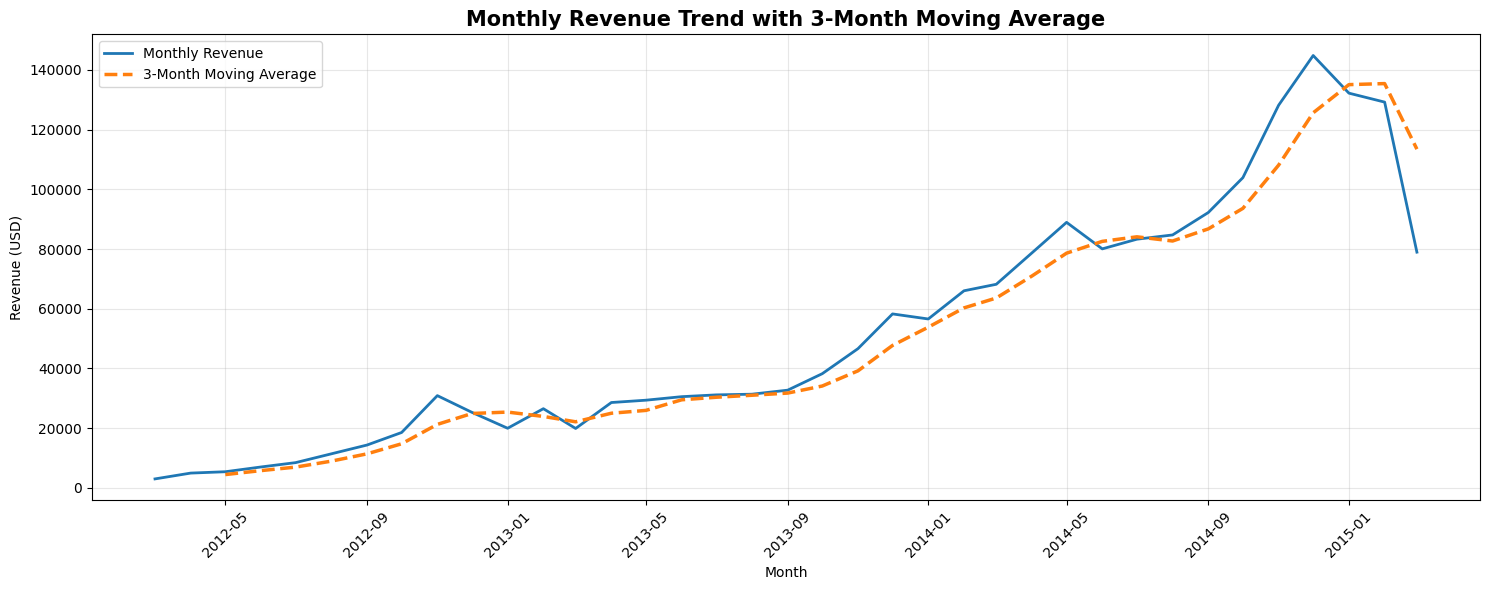

In [ ]:
# 6.1 Monthly Revenue Trend with Moving Average

monthly_revenue = (
    orders.set_index('created_at')
    .resample('MS')
    .agg(
        Total_Revenue=('price_usd', 'sum'),
        Total_Orders=('order_id', 'nunique')
    )
    .reset_index()
)

monthly_revenue['Revenue_3M_Moving_Average'] = (
    monthly_revenue['Total_Revenue']
    .rolling(window=3, min_periods=3)
    .mean()
)

plt.figure(figsize=(15, 6))

plt.plot(
    monthly_revenue['created_at'],
    monthly_revenue['Total_Revenue'],
    label='Monthly Revenue',
    linewidth=2
)

plt.plot(
    monthly_revenue['created_at'],
    monthly_revenue['Revenue_3M_Moving_Average'],
    label='3-Month Moving Average',
    linewidth=2.5,
    linestyle='--'
)

plt.title(
    'Monthly Revenue Trend with 3-Month Moving Average',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Month')
plt.ylabel('Revenue (USD)')
plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 6.2 Marketing Channel Performance Analysis

**Business Question:**

Which marketing channels generate the highest revenue, and how efficiently do they convert website sessions into orders?

**Objective:**

Compare marketing channel revenue and conversion rates to identify high-performing acquisition channels and potential optimization opportunities.

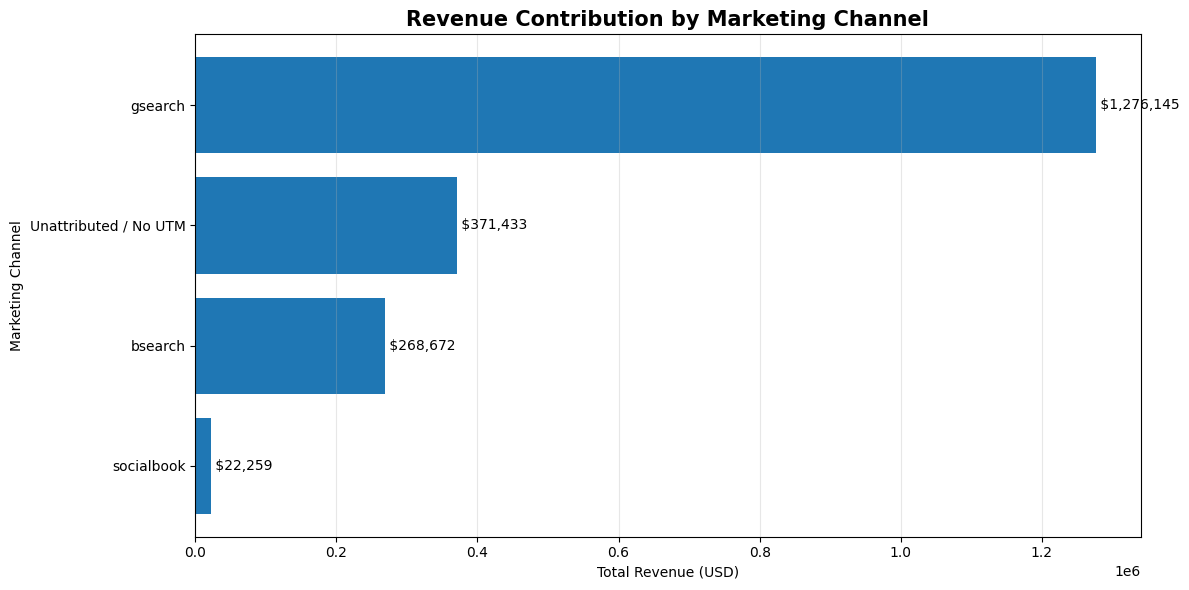

In [ ]:
# 6.2 Marketing Channel Performance Visualization

channel_chart = channel_business_performance.sort_values(
    'Total_Revenue',
    ascending=True
).copy()

plt.figure(figsize=(12, 6))

bars = plt.barh(
    channel_chart['Marketing_Channel'],
    channel_chart['Total_Revenue']
)

plt.title(
    'Revenue Contribution by Marketing Channel',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Total Revenue (USD)')
plt.ylabel('Marketing Channel')

for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f' ${width:,.0f}',
        va='center',
        ha='left'
    )

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

### 6.3 Device-Wise Revenue and Conversion Analysis

**Business Question:**

How differently do desktop and mobile visitors contribute to revenue and conversions?

**Objective:**

Compare device-level revenue, conversion rates and average order value to identify opportunities to improve the shopping experience.

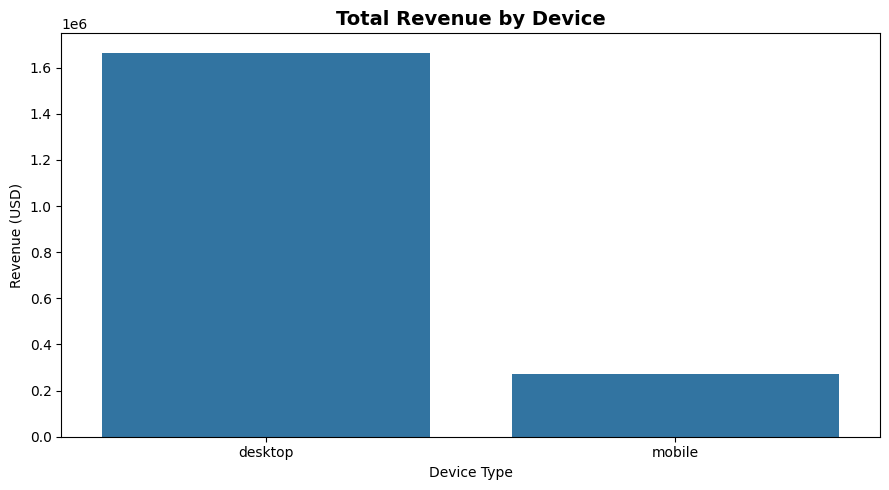

In [ ]:
# 6.3.1 Revenue by Device

device_chart = device_business_performance.sort_values(
    'Total_Revenue',
    ascending=False
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=device_chart,
    x='device_type',
    y='Total_Revenue'
)

plt.title('Total Revenue by Device', fontsize=14, fontweight='bold')
plt.xlabel('Device Type')
plt.ylabel('Revenue (USD)')
plt.tight_layout()
plt.show()

### 6.4 Landing Page Conversion Performance

**Business Question:**

Which landing pages convert visitors into customers most effectively, and which pages generate the highest revenue?

**Objective:**

Compare landing-page traffic, conversion rates and revenue to identify high-performing and underperforming landing pages.

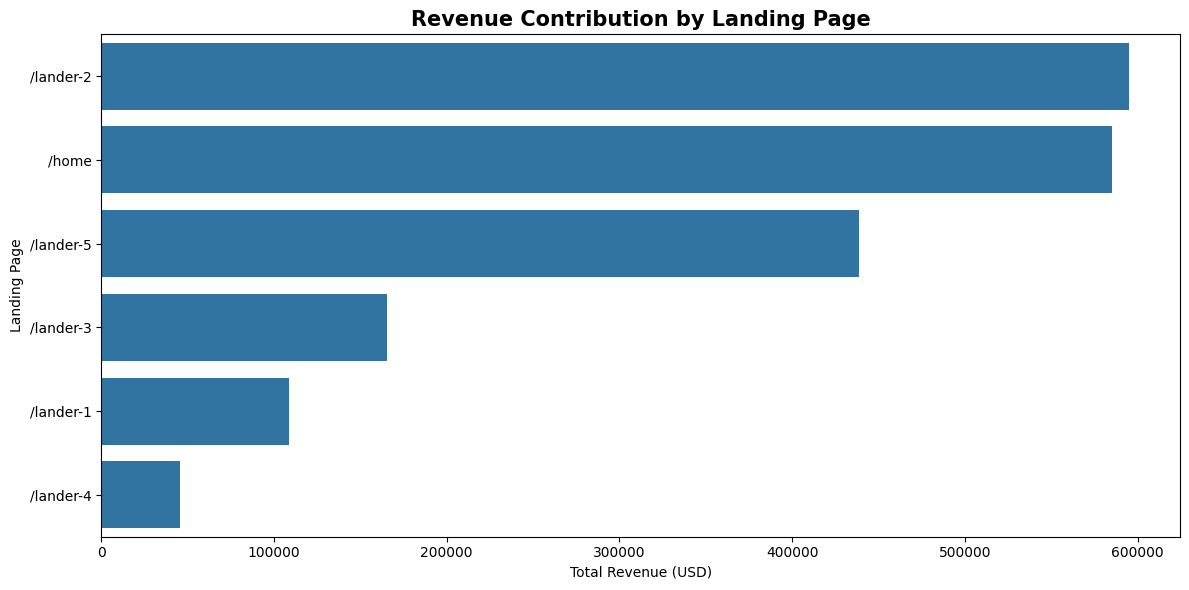

In [ ]:
# 6.4.1 Revenue by Landing Page

landing_chart = landing_page_performance.sort_values(
    'Total_Revenue',
    ascending=False
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=landing_chart,
    x='Total_Revenue',
    y='Landing_Page'
)

plt.title(
    'Revenue Contribution by Landing Page',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Total Revenue (USD)')
plt.ylabel('Landing Page')
plt.tight_layout()
plt.show()

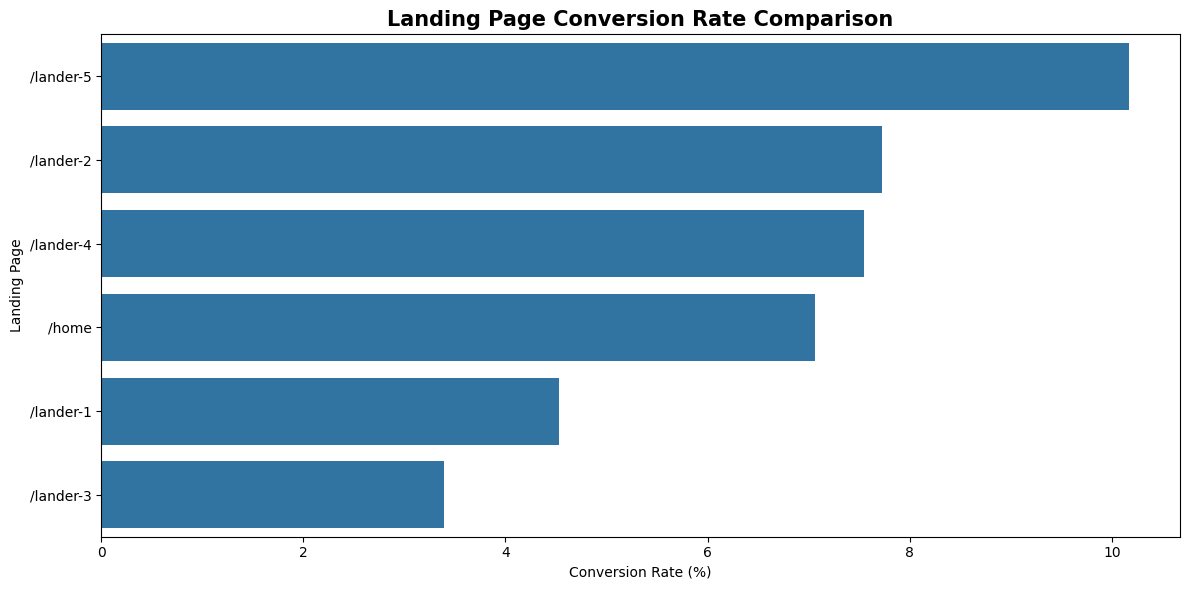

In [ ]:
# 6.4.2 Conversion Rate by Landing Page

landing_conversion = landing_page_performance.sort_values(
    'Conversion_Rate_%',
    ascending=False
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=landing_conversion,
    x='Conversion_Rate_%',
    y='Landing_Page'
)

plt.title(
    'Landing Page Conversion Rate Comparison',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Conversion Rate (%)')
plt.ylabel('Landing Page')
plt.tight_layout()
plt.show()

### 6.5 Customer Cohort Retention Heatmap

**Business Question:**

How does customer retention change across acquisition cohorts, and in which months do customers stop returning to purchase?

**Objective:**

Visualize monthly cohort retention percentages to identify retention patterns and understand long-term customer purchasing behavior.

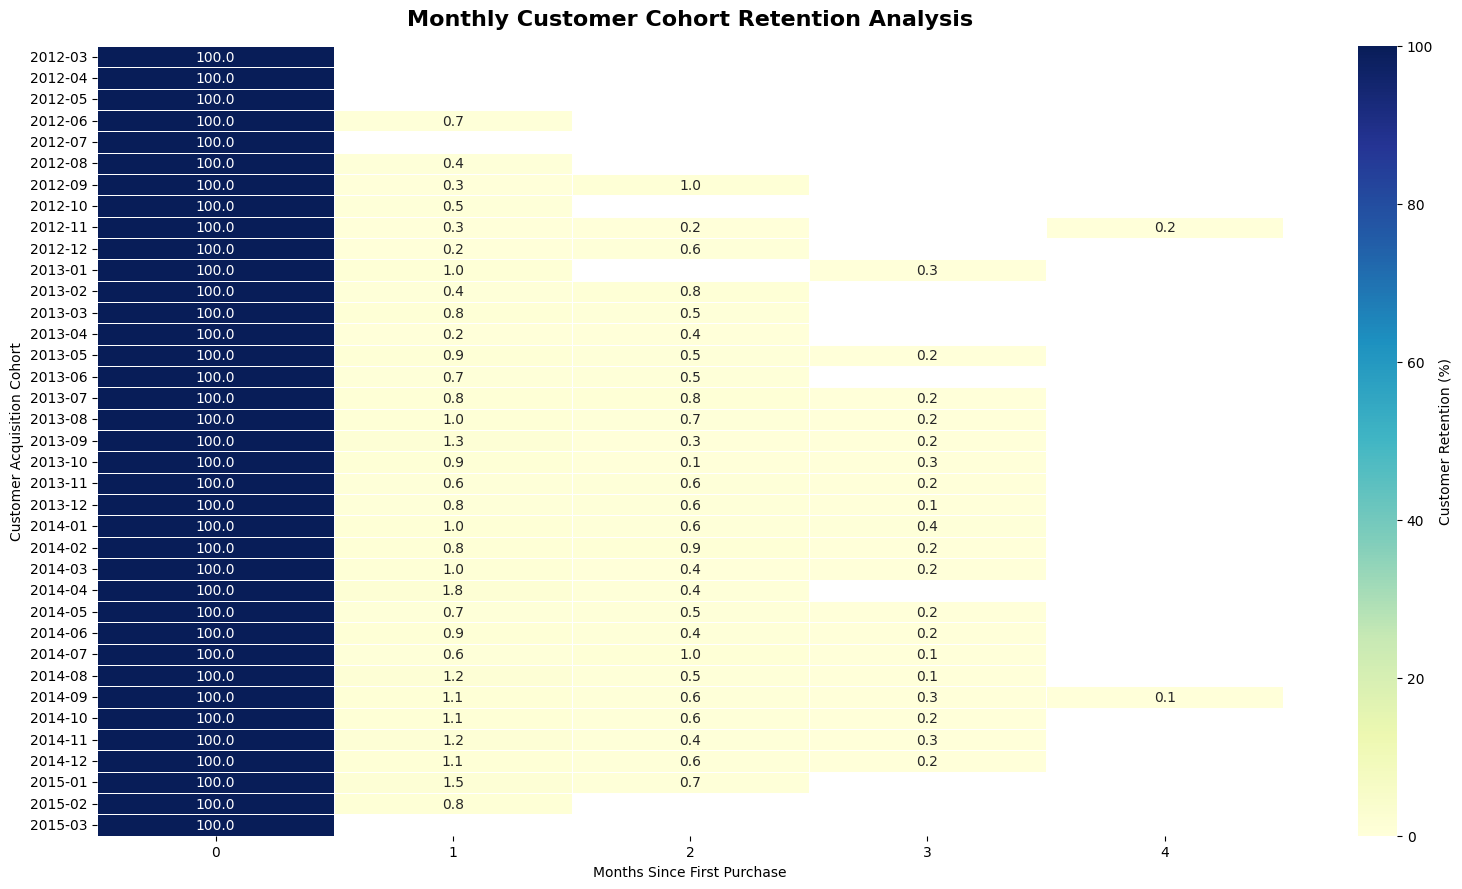

In [ ]:
# 6.5 Customer Cohort Retention Heatmap

plt.figure(figsize=(16, 9))

sns.heatmap(
    cohort_retention,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu',
    linewidths=0.5,
    vmin=0,
    vmax=100,
    cbar_kws={'label': 'Customer Retention (%)'}
)

plt.title(
    'Monthly Customer Cohort Retention Analysis',
    fontsize=16,
    fontweight='bold',
    pad=15
)

plt.xlabel('Months Since First Purchase')
plt.ylabel('Customer Acquisition Cohort')

plt.tight_layout()
plt.show()

### 6.6 Product Revenue and Profitability Analysis

**Business Question:**

Which products generate the highest revenue and gross profit, and which products deliver the strongest gross margins?

**Objective:**

Compare product-level revenue, gross profit and gross margin to identify the most financially valuable products.

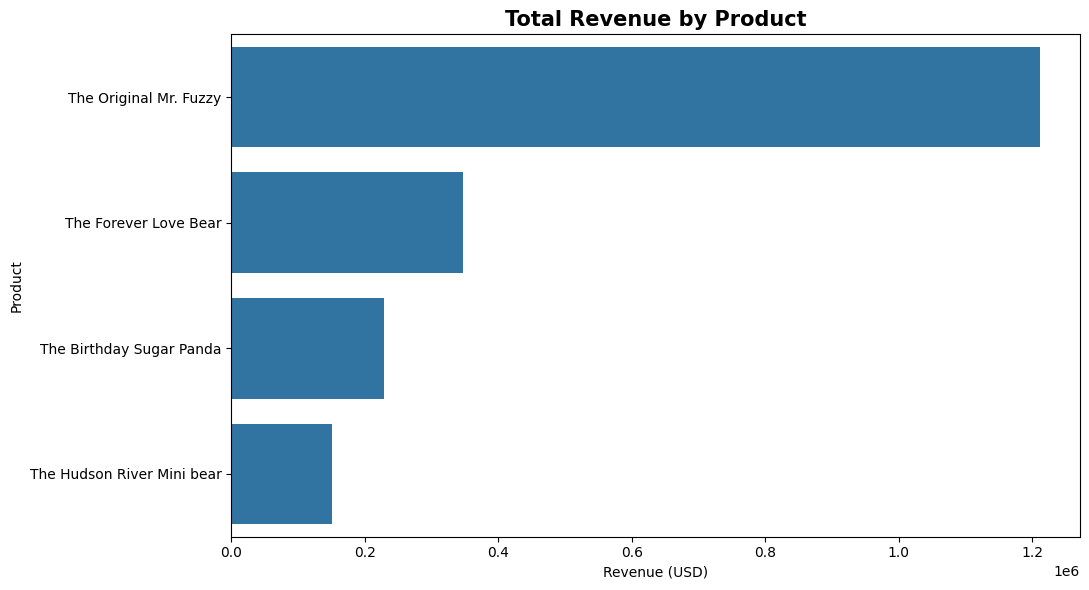

In [ ]:
# 6.6.1 Revenue by Product

product_chart = product_performance.merge(
    products[['product_id', 'product_name']],
    on='product_id',
    how='left'
)

product_chart = product_chart.sort_values(
    'Total_Revenue',
    ascending=False
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=product_chart,
    x='Total_Revenue',
    y='product_name'
)

plt.title('Total Revenue by Product', fontsize=15, fontweight='bold')
plt.xlabel('Revenue (USD)')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

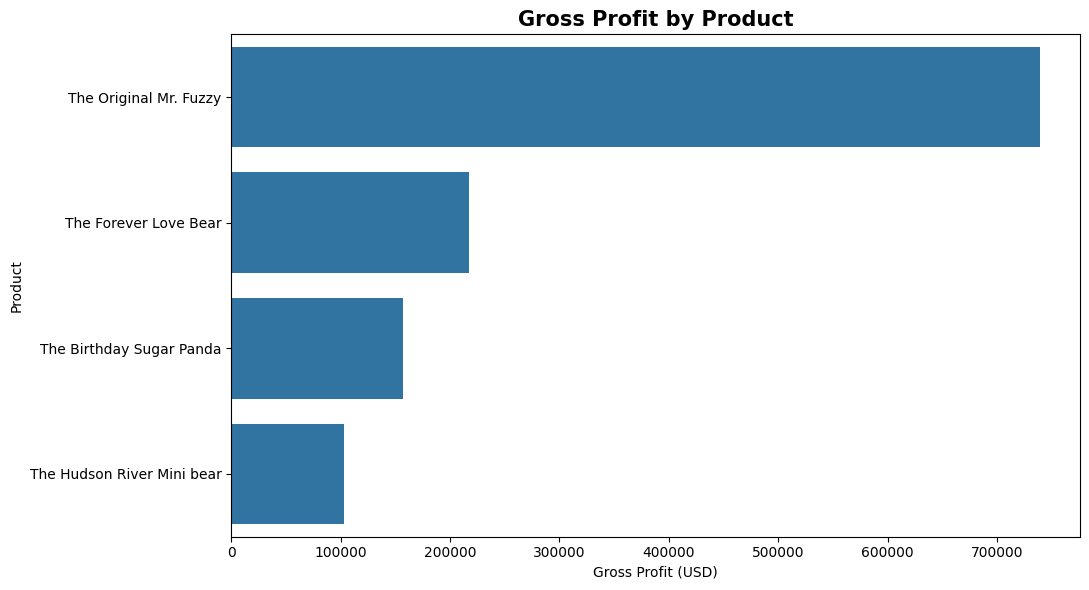

In [ ]:
# 6.6.2 Gross Profit by Product

plt.figure(figsize=(11, 6))

sns.barplot(
    data=product_chart.sort_values('Total_Gross_Profit', ascending=False),
    x='Total_Gross_Profit',
    y='product_name'
)

plt.title('Gross Profit by Product', fontsize=15, fontweight='bold')
plt.xlabel('Gross Profit (USD)')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

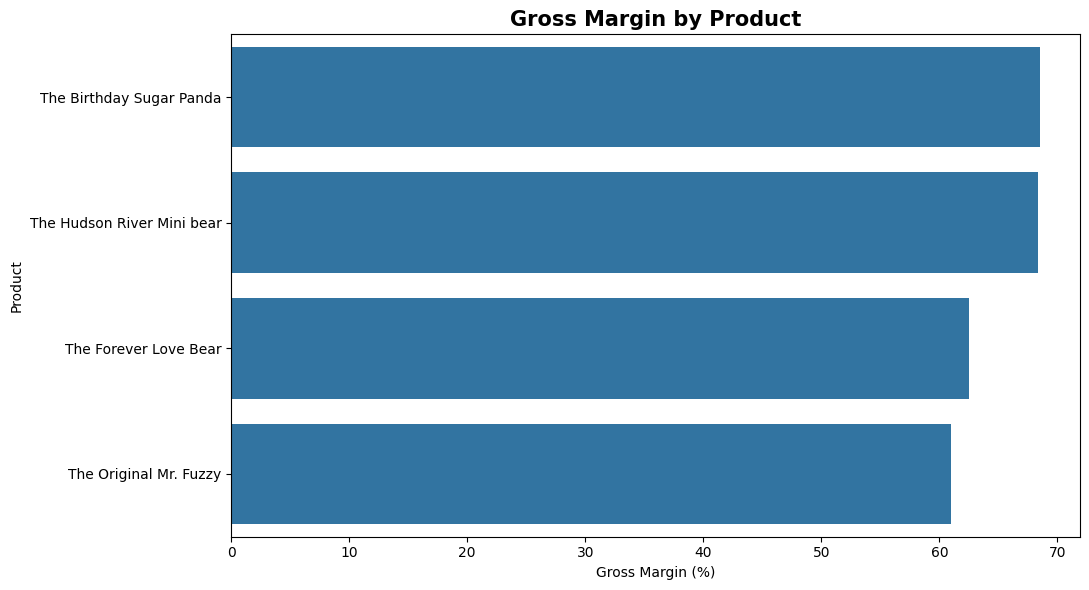

In [ ]:
# 6.6.3 Gross Margin by Product

plt.figure(figsize=(11, 6))

sns.barplot(
    data=product_chart.sort_values('Gross_Margin_%', ascending=False),
    x='Gross_Margin_%',
    y='product_name'
)

plt.title('Gross Margin by Product', fontsize=15, fontweight='bold')
plt.xlabel('Gross Margin (%)')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

### 6.7 Refund Performance and Product Risk Analysis

**Business Question:**

Which products have the highest refund rates, and how much revenue is being returned to customers?

**Objective:**

Identify products with elevated refund rates and compare their refund amounts to understand potential product and customer-experience risks.

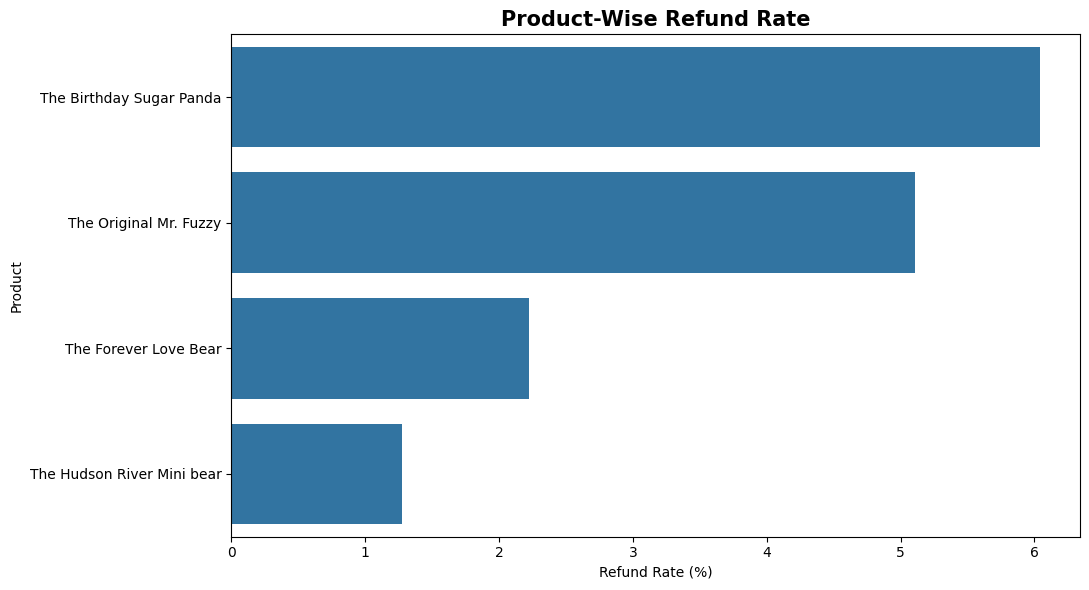

In [ ]:
# 6.7.1 Refund Rate by Product

refund_chart = product_refund_analysis.sort_values(
    'Refund_Rate_%',
    ascending=False
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=refund_chart,
    x='Refund_Rate_%',
    y='product_name'
)

plt.title('Product-Wise Refund Rate', fontsize=15, fontweight='bold')
plt.xlabel('Refund Rate (%)')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

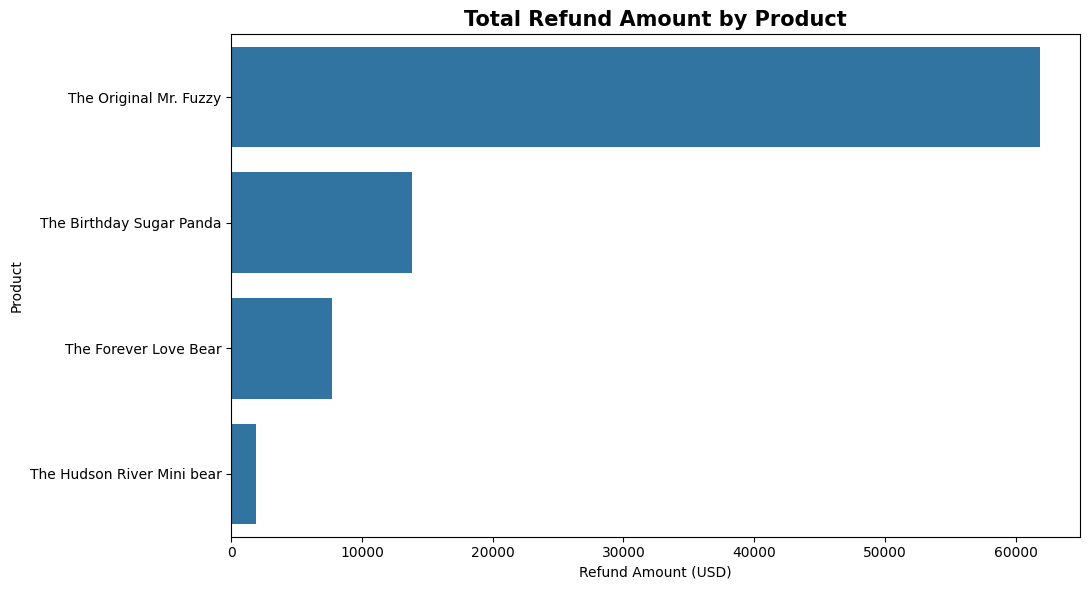

In [ ]:
# 6.7.2 Refund Amount by Product

plt.figure(figsize=(11, 6))

sns.barplot(
    data=refund_chart.sort_values(
        'Total_Refund_Amount',
        ascending=False
    ),
    x='Total_Refund_Amount',
    y='product_name'
)

plt.title('Total Refund Amount by Product', fontsize=15, fontweight='bold')
plt.xlabel('Refund Amount (USD)')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

### 6.8 Customer Purchasing Behavior Analysis

**Business Question:**

How do one-time buyers and repeat buyers differ in customer count, order frequency and revenue contribution?

**Objective:**

Compare customer segments to understand purchasing frequency, customer value and opportunities to improve customer retention.

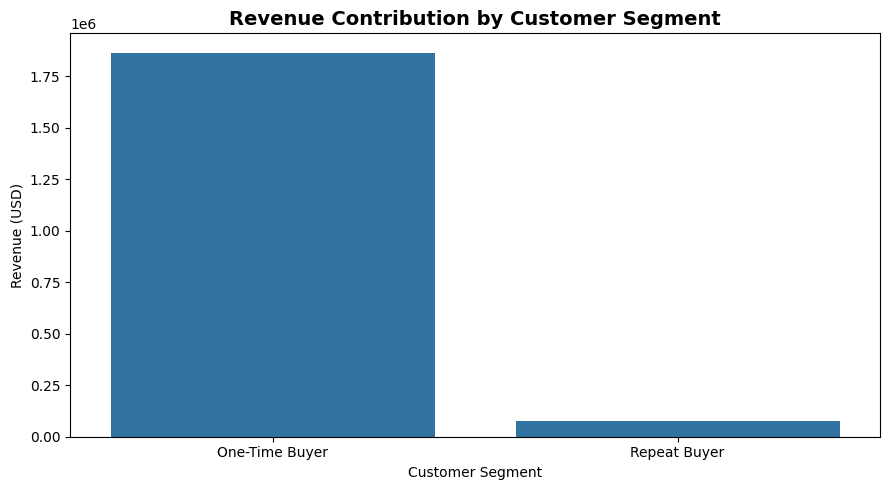

In [ ]:
# 6.8.1 Revenue Contribution by Customer Segment

plt.figure(figsize=(9, 5))

sns.barplot(
    data=customer_segments,
    x='Customer_Segment',
    y='Total_Revenue'
)

plt.title(
    'Revenue Contribution by Customer Segment',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Customer Segment')
plt.ylabel('Revenue (USD)')
plt.tight_layout()
plt.show()

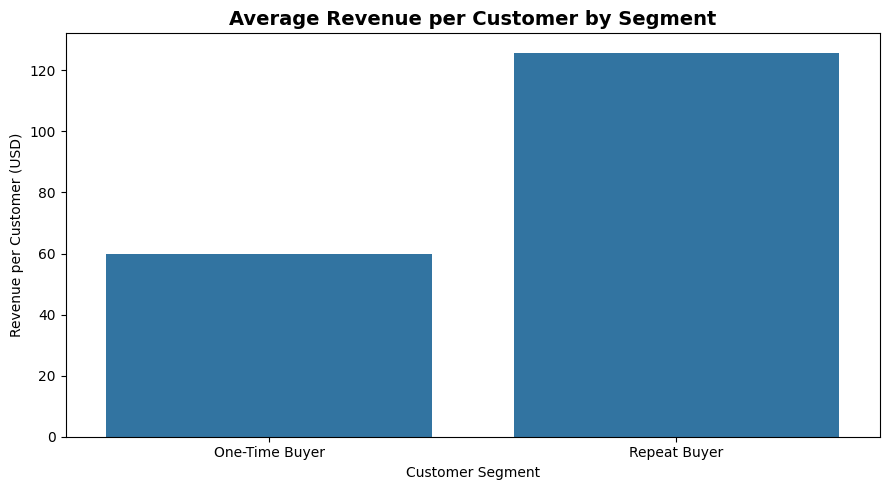

In [ ]:
# 6.8.2 Average Revenue per Customer

plt.figure(figsize=(9, 5))

sns.barplot(
    data=customer_segments,
    x='Customer_Segment',
    y='Revenue_Per_Customer'
)

plt.title(
    'Average Revenue per Customer by Segment',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Customer Segment')
plt.ylabel('Revenue per Customer (USD)')
plt.tight_layout()
plt.show()

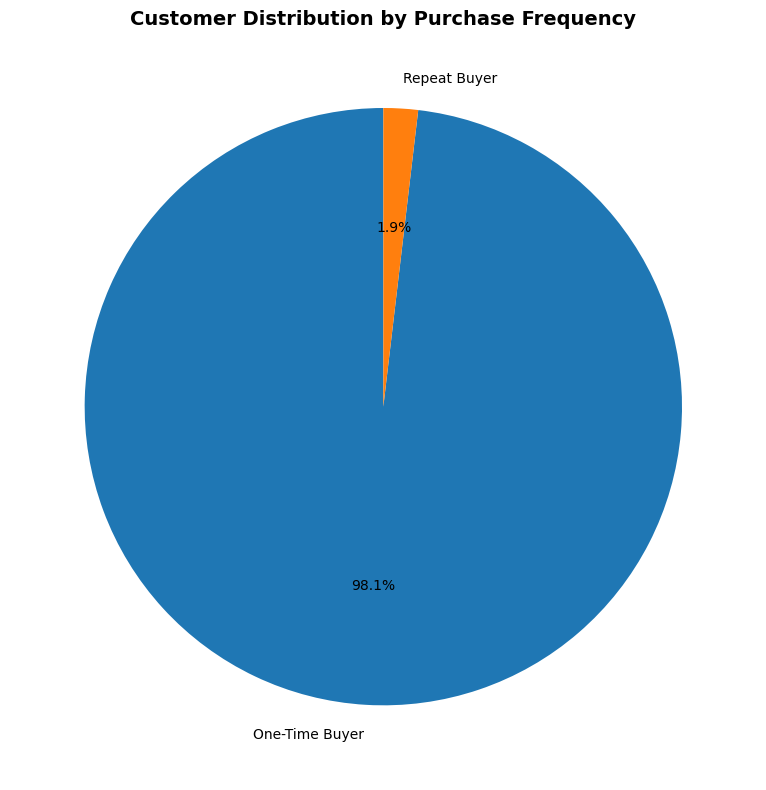

In [ ]:
# 6.8.3 Customer Distribution by Segment

plt.figure(figsize=(8, 8))

plt.pie(
    customer_segments['Total_Customers'],
    labels=customer_segments['Customer_Segment'],
    autopct='%1.1f%%',
    startangle=90
)

plt.title(
    'Customer Distribution by Purchase Frequency',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

### 6.9 Time Between First and Second Purchase Analysis

**Business Question:**

How long does it take customers to make their second purchase after their first order?

**Objective:**

Analyze the time between first and second purchases to understand repeat-purchase timing and identify opportunities for customer re-engagement campaigns.

In [ ]:
# 6.9 Time Between First and Second Purchase Analysis

customer_purchase_dates = (
    orders.sort_values(['user_id', 'created_at'])
    .groupby('user_id')
    .agg(
        First_Purchase=('created_at', 'min'),
        Second_Purchase=('created_at', lambda x: x.iloc[1] if len(x) > 1 else pd.NaT),
        Total_Orders=('order_id', 'nunique')
    )
    .reset_index()
)

repeat_purchase_timing = customer_purchase_dates.dropna(
    subset=['Second_Purchase']
).copy()

repeat_purchase_timing['Days_To_Second_Purchase'] = (
    repeat_purchase_timing['Second_Purchase'] -
    repeat_purchase_timing['First_Purchase']
).dt.days

print("Customers with Repeat Purchases:",
      len(repeat_purchase_timing))

print("\nTime Between First and Second Purchase:")
display(
    repeat_purchase_timing['Days_To_Second_Purchase']
    .describe()
    .round(2)
)

Customers with Repeat Purchases: 591

Time Between First and Second Purchase:


,Days_To_Second_Purchase
count,591.00
mean,34.68
std,22.64
min,0.00
25%,16.00
50%,31.00
75%,50.00
max,106.00


### 6.10 Monthly Website Traffic vs Revenue Analysis

**Business Question:**

Does an increase in website sessions translate into higher revenue? Are traffic growth and revenue growth moving together?

**Objective:**

Compare monthly website sessions, orders and revenue to understand how effectively website traffic translates into business results.

In [ ]:
# 6.10 Monthly Website Traffic vs Revenue Analysis

monthly_traffic = (
    website_sessions
    .set_index('created_at')
    .resample('MS')
    .agg(
        Total_Sessions=('website_session_id', 'nunique')
    )
    .reset_index()
)

monthly_sales = (
    orders
    .set_index('created_at')
    .resample('MS')
    .agg(
        Total_Orders=('order_id', 'nunique'),
        Total_Revenue=('price_usd', 'sum')
    )
    .reset_index()
)

monthly_business_performance = monthly_traffic.merge(
    monthly_sales,
    on='created_at',
    how='outer',
    validate='one_to_one'
).sort_values('created_at')

monthly_business_performance['Conversion_Rate_%'] = (
    monthly_business_performance['Total_Orders'] /
    monthly_business_performance['Total_Sessions']
) * 100

display(monthly_business_performance.round(2))

,created_at,Total_Sessions,Total_Orders,Total_Revenue,Conversion_Rate_%
0,2012-03-01,1879,60,2999.40,3.19
1,2012-04-01,3734,99,4949.01,2.65
2,2012-05-01,3736,108,5398.92,2.89
3,2012-06-01,3963,140,6998.60,3.53
4,2012-07-01,4249,169,8448.31,3.98
5,2012-08-01,6097,228,11397.72,3.74
6,2012-09-01,6546,287,14347.13,4.38
7,2012-10-01,8183,371,18546.29,4.53
8,2012-11-01,14011,618,30893.82,4.41
9,2012-12-01,10072,506,25294.94,5.02


### 6.11 Monthly Order and Revenue Growth

**Business Question:**

How are monthly order volume and revenue growing or declining over time?

**Objective:**

Calculate month-over-month order and revenue growth rates and visualize their trends to identify business growth patterns.

In [ ]:
# 6.11 Monthly Order and Revenue Growth Analysis

monthly_growth = (
    orders.set_index('created_at')
    .resample('MS')
    .agg(
        Total_Orders=('order_id', 'nunique'),
        Total_Revenue=('price_usd', 'sum')
    )
    .reset_index()
)

monthly_growth['Order_Growth_%'] = (
    monthly_growth['Total_Orders'].pct_change() * 100
)

monthly_growth['Revenue_Growth_%'] = (
    monthly_growth['Total_Revenue'].pct_change() * 100
)

display(monthly_growth.round(2))

,created_at,Total_Orders,Total_Revenue,Order_Growth_%,Revenue_Growth_%
0,2012-03-01,60,2999.40,NaN,NaN
1,2012-04-01,99,4949.01,65.00,65.00
2,2012-05-01,108,5398.92,9.09,9.09
3,2012-06-01,140,6998.60,29.63,29.63
4,2012-07-01,169,8448.31,20.71,20.71
5,2012-08-01,228,11397.72,34.91,34.91
6,2012-09-01,287,14347.13,25.88,25.88
7,2012-10-01,371,18546.29,29.27,29.27
8,2012-11-01,618,30893.82,66.58,66.58
9,2012-12-01,506,25294.94,-18.12,-18.12


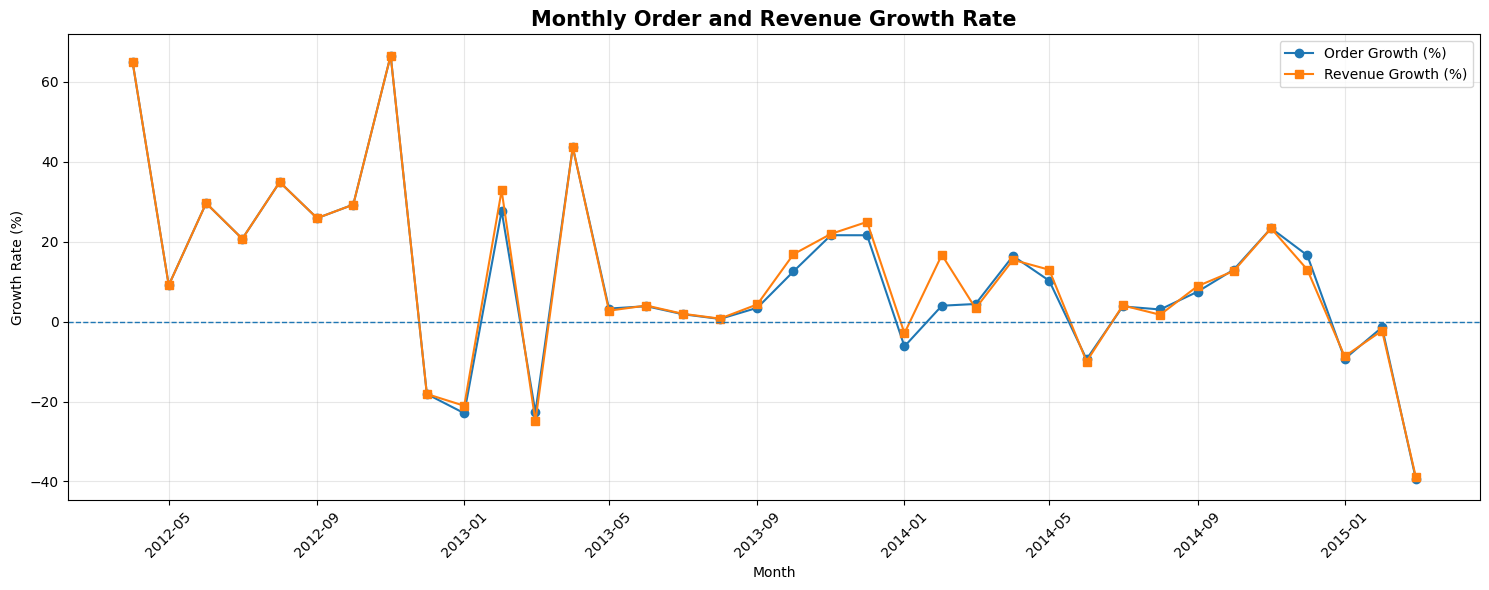

In [ ]:
# Monthly Growth Rate Visualization

plt.figure(figsize=(15, 6))

plt.plot(
    monthly_growth['created_at'],
    monthly_growth['Order_Growth_%'],
    marker='o',
    label='Order Growth (%)'
)

plt.plot(
    monthly_growth['created_at'],
    monthly_growth['Revenue_Growth_%'],
    marker='s',
    label='Revenue Growth (%)'
)

plt.axhline(y=0, linestyle='--', linewidth=1)

plt.title(
    'Monthly Order and Revenue Growth Rate',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Month')
plt.ylabel('Growth Rate (%)')
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 6.12 Product Sales Contribution – Pareto Analysis

**Business Question:**

Which products contribute the largest share of total revenue, and how concentrated is revenue across the product portfolio?

**Objective:**

Rank products by revenue, calculate cumulative revenue contribution and visualize cumulative revenue contribution across products.

In [ ]:
# 6.12 Product Sales Contribution – Pareto Analysis

pareto_data = (
    order_items.groupby('product_id')
    .agg(Total_Revenue=('price_usd', 'sum'))
    .reset_index()
    .merge(
        products[['product_id', 'product_name']],
        on='product_id',
        how='left'
    )
    .sort_values('Total_Revenue', ascending=False)
    .reset_index(drop=True)
)

pareto_data['Revenue_Share_%'] = (
    pareto_data['Total_Revenue'] /
    pareto_data['Total_Revenue'].sum()
) * 100

pareto_data['Cumulative_Revenue_%'] = (
    pareto_data['Revenue_Share_%'].cumsum()
)

display(pareto_data.round(2))

,product_id,Total_Revenue,product_name,Revenue_Share_%,Cumulative_Revenue_%
0,1,1211057.74,The Original Mr. Fuzzy,62.47,62.47
1,2,347702.04,The Forever Love Bear,17.94,80.41
2,3,229260.15,The Birthday Sugar Panda,11.83,92.24
3,4,150489.82,The Hudson River Mini bear,7.76,100.00


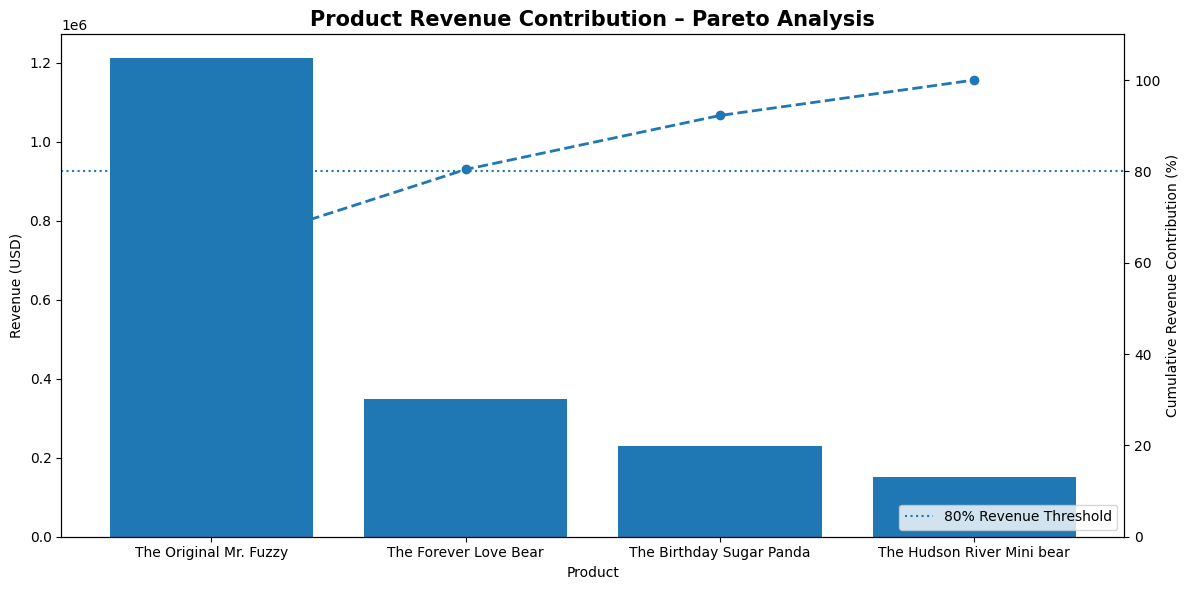

In [ ]:
# Pareto Chart

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.bar(
    pareto_data['product_name'],
    pareto_data['Total_Revenue']
)

ax1.set_xlabel('Product')
ax1.set_ylabel('Revenue (USD)')

ax2 = ax1.twinx()

ax2.plot(
    pareto_data['product_name'],
    pareto_data['Cumulative_Revenue_%'],
    marker='o',
    linestyle='--',
    linewidth=2
)

ax2.axhline(
    80,
    linestyle=':',
    linewidth=1.5,
    label='80% Revenue Threshold'
)

ax2.set_ylabel('Cumulative Revenue Contribution (%)')
ax2.set_ylim(0, 110)

plt.title(
    'Product Revenue Contribution – Pareto Analysis',
    fontsize=15,
    fontweight='bold'
)

ax2.legend(loc='lower right')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

### 6.13 Monthly Refund Trend and Refund Rate Analysis

**Business Question:**

How does the monthly refund amount compare with monthly sales revenue, and are refund rates increasing or decreasing?

**Objective:**

Analyze monthly refund amounts, refunded items and refund rates to identify periods with higher refund activity.

In [ ]:
# Convert Order Items creation date to datetime

order_items['created_at'] = pd.to_datetime(
    order_items['created_at'],
    errors='coerce'
)

print("Order Items Date Type:",
      order_items['created_at'].dtype)

print("Missing Dates:",
      order_items['created_at'].isna().sum())

print("Date Range:")
print(order_items['created_at'].min())
print(order_items['created_at'].max())

Order Items Date Type: datetime64[ns]
Missing Dates: 0
Date Range:
2012-03-19 10:42:46
2015-03-19 05:38:31


In [ ]:
# 6.13 Monthly Refund Trend and Refund Rate Analysis

# Monthly refund amounts and distinct refunded items
monthly_refund_metrics = (
    order_item_refunds
    .set_index('created_at')
    .resample('MS')
    .agg(
        Refund_Amount=('refund_amount_usd', 'sum'),
        Refunded_Items=('order_item_id', 'nunique')
    )
    .reset_index()
)

# Monthly sales revenue and distinct items sold
monthly_sales_metrics = (
    order_items
    .set_index('created_at')
    .resample('MS')
    .agg(
        Sales_Revenue=('price_usd', 'sum'),
        Items_Sold=('order_item_id', 'nunique')
    )
    .reset_index()
)

# Combine monthly metrics
monthly_refund_performance = monthly_sales_metrics.merge(
    monthly_refund_metrics,
    on='created_at',
    how='left',
    validate='one_to_one'
)

monthly_refund_performance[
    ['Refund_Amount', 'Refunded_Items']
] = monthly_refund_performance[
    ['Refund_Amount', 'Refunded_Items']
].fillna(0)

# Calculate refund metrics
monthly_refund_performance['Item_Refund_Rate_%'] = (
    monthly_refund_performance['Refunded_Items'] /
    monthly_refund_performance['Items_Sold']
) * 100

monthly_refund_performance['Refund_Amount_Rate_%'] = (
    monthly_refund_performance['Refund_Amount'] /
    monthly_refund_performance['Sales_Revenue']
) * 100

display(monthly_refund_performance.round(2))

,created_at,Sales_Revenue,Items_Sold,Refund_Amount,Refunded_Items,Item_Refund_Rate_%,Refund_Amount_Rate_%
0,2012-03-01,2999.40,60,0.00,0.0,0.00,0.00
1,2012-04-01,4949.01,99,249.95,5.0,5.05,5.05
2,2012-05-01,5398.92,108,249.95,5.0,4.63,4.63
3,2012-06-01,6998.60,140,249.95,5.0,3.57,3.57
4,2012-07-01,8448.31,169,649.87,13.0,7.69,7.69
5,2012-08-01,11397.72,228,899.82,18.0,7.89,7.89
6,2012-09-01,14347.13,287,1049.79,21.0,7.32,7.32
7,2012-10-01,18546.29,371,1199.76,24.0,6.47,6.47
8,2012-11-01,30893.82,618,1999.60,40.0,6.47,6.47
9,2012-12-01,25294.94,506,1899.62,38.0,7.51,7.51


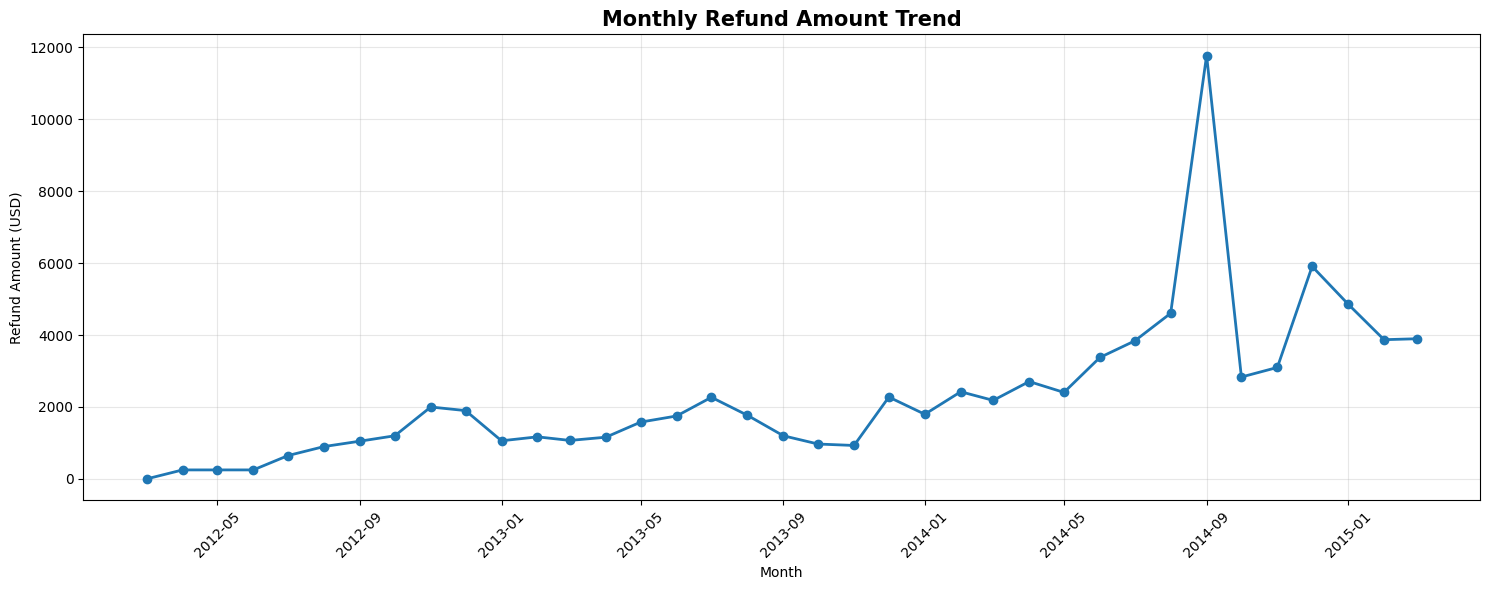

In [ ]:
# Monthly Refund Amount Trend

plt.figure(figsize=(15, 6))

plt.plot(
    monthly_refund_performance['created_at'],
    monthly_refund_performance['Refund_Amount'],
    marker='o',
    linewidth=2
)

plt.title(
    'Monthly Refund Amount Trend',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Month')
plt.ylabel('Refund Amount (USD)')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

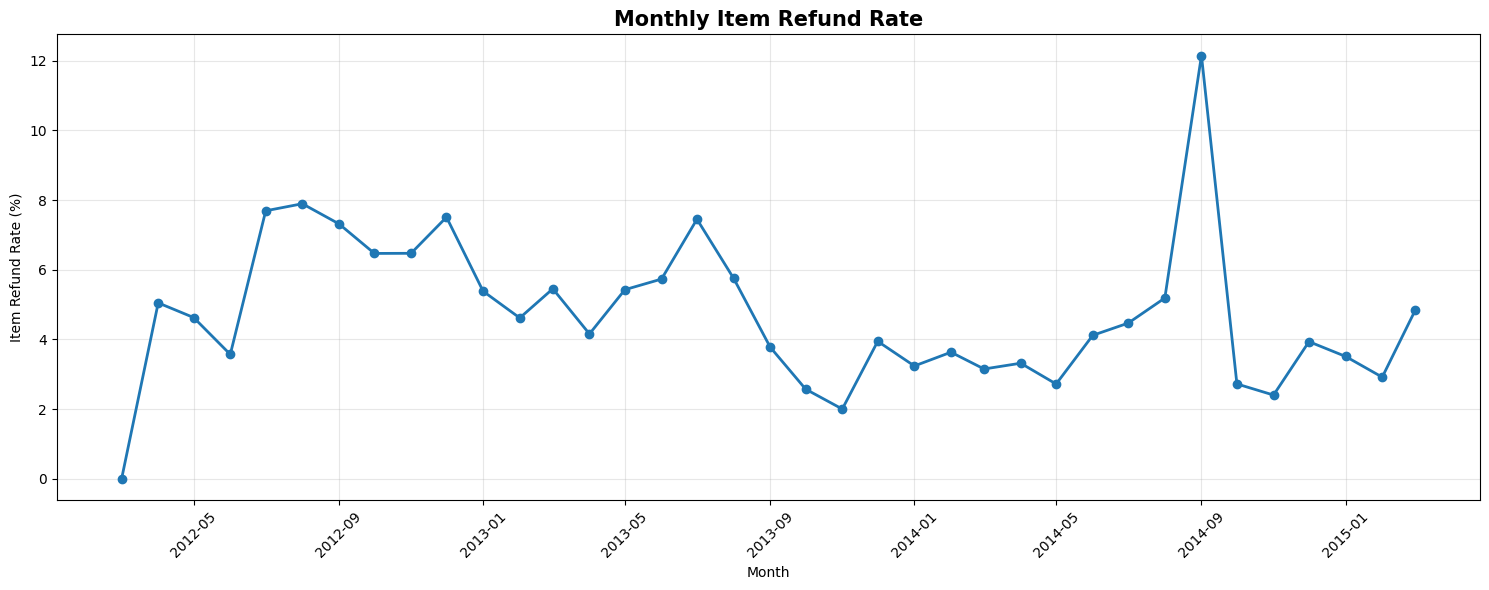

In [ ]:
# Monthly Item Refund Rate Trend

plt.figure(figsize=(15, 6))

plt.plot(
    monthly_refund_performance['created_at'],
    monthly_refund_performance['Item_Refund_Rate_%'],
    marker='o',
    linewidth=2
)

plt.title(
    'Monthly Item Refund Rate',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Month')
plt.ylabel('Item Refund Rate (%)')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 6.14 Website Conversion Funnel Visualization

**Business Question:**

At which stage of the shopping journey do visitors drop off most significantly?

**Objective:**

Visualize session counts across the shopping funnel to identify the stages where the business loses potential customers.

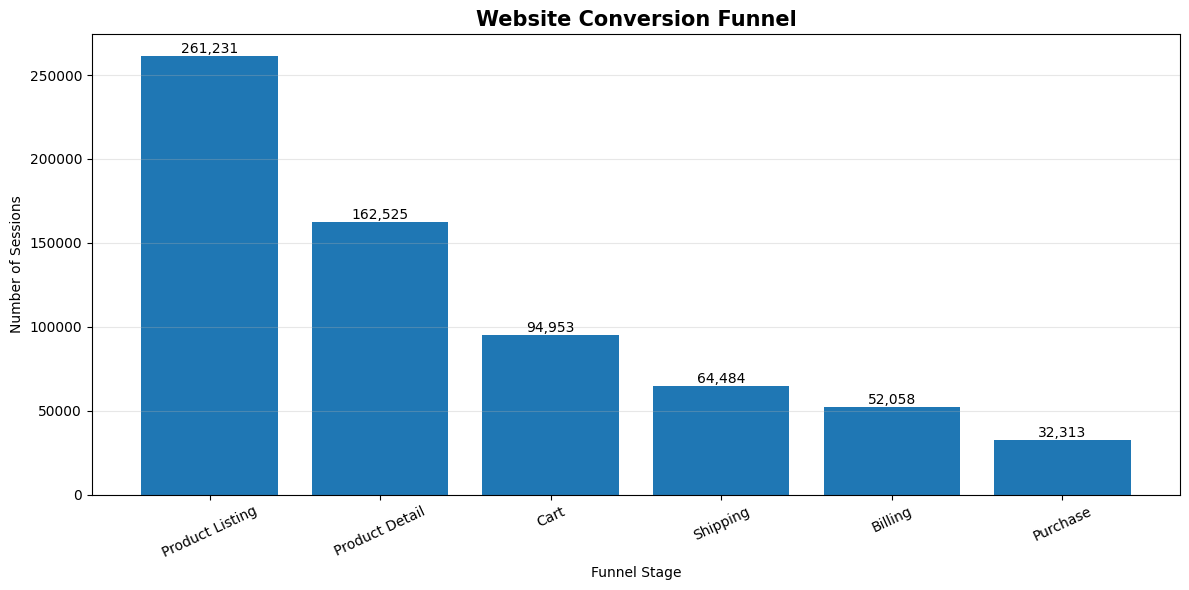

In [ ]:
# 6.14 Website Conversion Funnel Visualization

funnel_chart = funnel_analysis.copy()

plt.figure(figsize=(12, 6))

bars = plt.bar(
    funnel_chart['Funnel_Stage'],
    funnel_chart['Sessions']
)

plt.title(
    'Website Conversion Funnel',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Funnel Stage')
plt.ylabel('Number of Sessions')

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f'{height:,.0f}',
        ha='center',
        va='bottom'
    )

plt.xticks(rotation=25)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 6.15 Customer Revenue Segmentation Analysis

**Business Question:**

How is revenue distributed across customers with different purchasing frequencies, and how much revenue do repeat customers contribute?

**Objective:**

Segment customers by purchase frequency and compare customer count, total revenue and average revenue per customer to identify valuable customer groups.

In [ ]:
# 6.15 Customer Revenue Segmentation Analysis

customer_revenue_segments = (
    orders.groupby('user_id')
    .agg(
        Total_Orders=('order_id', 'nunique'),
        Total_Revenue=('price_usd', 'sum')
    )
    .reset_index()
)

# Create purchasing frequency segments
customer_revenue_segments['Customer_Segment'] = np.select(
    [
        customer_revenue_segments['Total_Orders'] == 1,
        customer_revenue_segments['Total_Orders'] == 2,
        customer_revenue_segments['Total_Orders'] >= 3
    ],
    [
        'One-Time Buyers',
        'Two-Time Buyers',
        'Frequent Buyers (3+)'
    ],
    default='Unclassified'
)

# Calculate segment performance
segment_performance = (
    customer_revenue_segments
    .groupby('Customer_Segment')
    .agg(
        Total_Customers=('user_id', 'nunique'),
        Total_Orders=('Total_Orders', 'sum'),
        Total_Revenue=('Total_Revenue', 'sum')
    )
    .reset_index()
)

segment_performance['Revenue_Per_Customer'] = (
    segment_performance['Total_Revenue'] /
    segment_performance['Total_Customers']
)

segment_performance['Revenue_Share_%'] = (
    segment_performance['Total_Revenue'] /
    segment_performance['Total_Revenue'].sum()
) * 100

segment_performance['Customer_Share_%'] = (
    segment_performance['Total_Customers'] /
    segment_performance['Total_Customers'].sum()
) * 100

display(segment_performance.round(2))

,Customer_Segment,Total_Customers,Total_Orders,Total_Revenue,Revenue_Per_Customer,Revenue_Share_%,Customer_Share_%
0,Frequent Buyers (3+),26,78,4669.04,179.58,0.24,0.08
1,One-Time Buyers,31105,31105,1864153.31,59.93,96.16,98.14
2,Two-Time Buyers,565,1130,69687.40,123.34,3.59,1.78


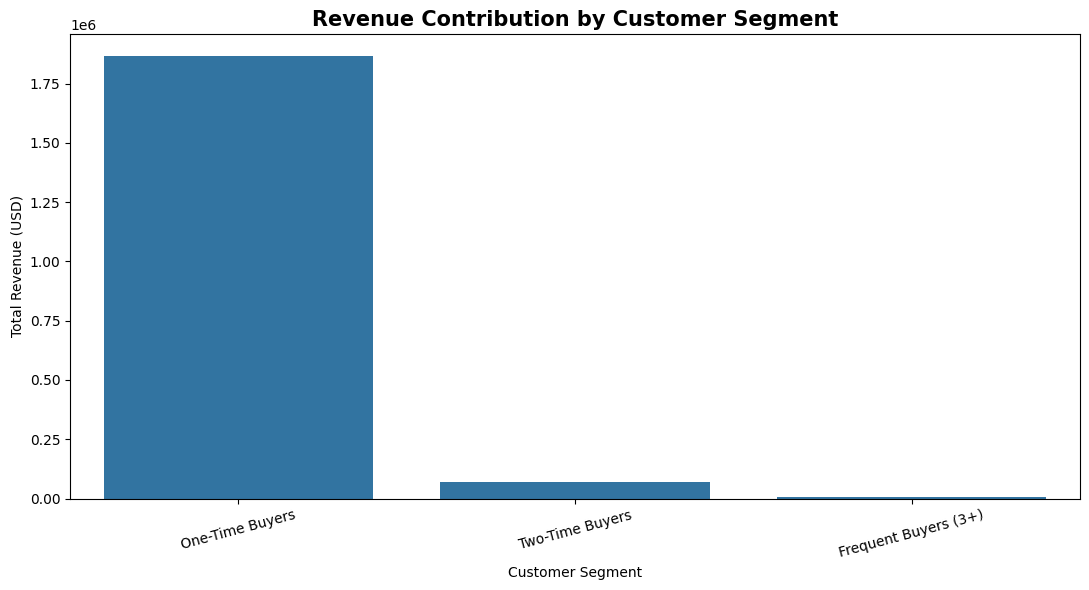

In [ ]:
# Revenue Contribution by Customer Segment

segment_chart = segment_performance.sort_values(
    'Total_Revenue',
    ascending=False
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=segment_chart,
    x='Customer_Segment',
    y='Total_Revenue'
)

plt.title(
    'Revenue Contribution by Customer Segment',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Customer Segment')
plt.ylabel('Total Revenue (USD)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

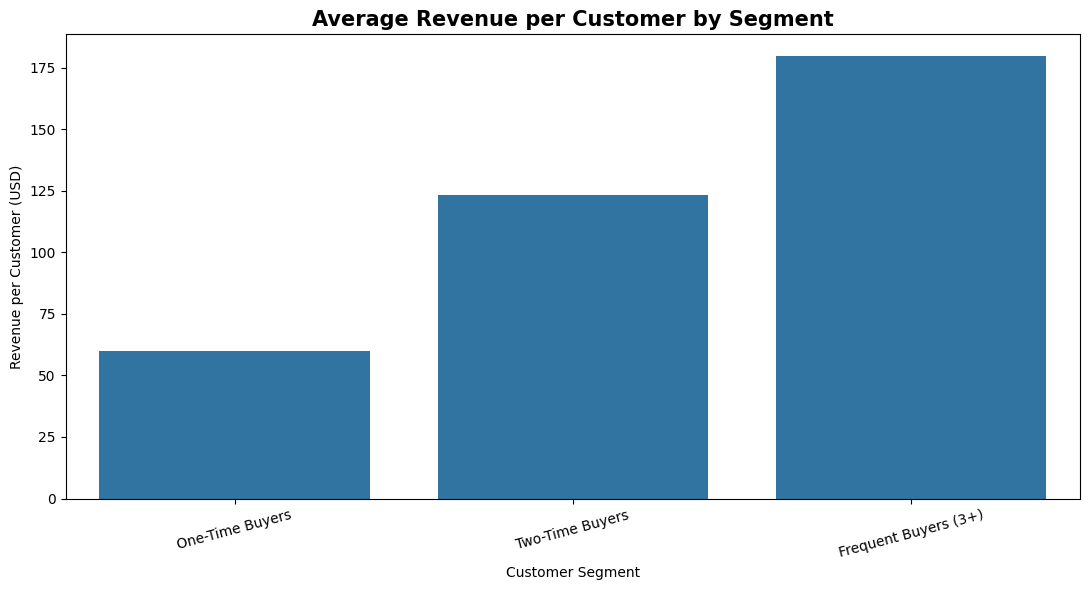

In [ ]:
# Average Revenue per Customer by Segment

plt.figure(figsize=(11, 6))

sns.barplot(
    data=segment_chart,
    x='Customer_Segment',
    y='Revenue_Per_Customer'
)

plt.title(
    'Average Revenue per Customer by Segment',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Customer Segment')
plt.ylabel('Revenue per Customer (USD)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 7. FINAL PYTHON DATA VALIDATION

**Objective:**

Perform final data-quality checks, validate relationships between datasets and reconcile Python calculations with SQL Server results before preparing business insights and recommendations.

In [ ]:
# 7.1 Final Dataset Validation Summary

datasets = {
    'Orders': orders,
    'Order Items': order_items,
    'Order Item Refunds': order_item_refunds,
    'Products': products,
    'Website Pageviews': website_pageviews,
    'Website Sessions': website_sessions
}

primary_keys = {
    'Orders': 'order_id',
    'Order Items': 'order_item_id',
    'Order Item Refunds': 'order_item_refund_id',
    'Products': 'product_id',
    'Website Pageviews': 'website_pageview_id',
    'Website Sessions': 'website_session_id'
}

validation_results = []

for name, df in datasets.items():

    key = primary_keys[name]

    validation_results.append({
        'Dataset': name,
        'Rows': len(df),
        'Columns': len(df.columns),
        'Missing_Values': df.isnull().sum().sum(),
        'Duplicate_Rows': df.duplicated().sum(),
        'Duplicate_Primary_Keys': df[key].duplicated().sum()
    })

final_validation_summary = pd.DataFrame(validation_results)

display(final_validation_summary)

,Dataset,Rows,Columns,Missing_Values,Duplicate_Rows,Duplicate_Primary_Keys
0,Orders,32313,8,0,0,0
1,Order Items,40025,9,0,0,0
2,Order Item Refunds,1731,5,0,0,0
3,Products,4,3,0,0,0
4,Website Pageviews,1188124,4,0,0,0
5,Website Sessions,472871,9,289901,0,0


7.2 Referential Integrity Validation
Objective: Verify that foreign keys in child datasets match their corresponding primary keys in parent datasets.

In [ ]:
# 7.2 Referential Integrity Validation

integrity_checks = {
    'Orders → Website Sessions': (
        orders['website_session_id'].isin(
            website_sessions['website_session_id']
        ).sum(),
        len(orders)
    ),

    'Order Items → Orders': (
        order_items['order_id'].isin(
            orders['order_id']
        ).sum(),
        len(order_items)
    ),

    'Refunds → Order Items': (
        order_item_refunds['order_item_id'].isin(
            order_items['order_item_id']
        ).sum(),
        len(order_item_refunds)
    ),

    'Pageviews → Website Sessions': (
        website_pageviews['website_session_id'].isin(
            website_sessions['website_session_id']
        ).sum(),
        len(website_pageviews)
    ),

    'Order Items → Products': (
        order_items['product_id'].isin(
            products['product_id']
        ).sum(),
        len(order_items)
    )
}

integrity_results = []

for relationship, (matched, total) in integrity_checks.items():
    integrity_results.append({
        'Relationship': relationship,
        'Total_Records': total,
        'Matched_Records': matched,
        'Unmatched_Records': total - matched,
        'Match_Rate_%': matched / total * 100
    })

integrity_summary = pd.DataFrame(integrity_results)

display(integrity_summary.round(2))

,Relationship,Total_Records,Matched_Records,Unmatched_Records,Match_Rate_%
0,Orders → Website Sessions,32313,32313,0,100.0
1,Order Items → Orders,40025,40025,0,100.0
2,Refunds → Order Items,1731,1731,0,100.0
3,Pageviews → Website Sessions,1188124,1188124,0,100.0
4,Order Items → Products,40025,40025,0,100.0


### 7.3 SQL–Python Financial Reconciliation

**Objective:**

Compare key business metrics calculated in Python against the corresponding SQL Server analysis to ensure consistency and reliability across analytical tools.

In [ ]:
# 7.3 SQL–Python Reconciliation: Python Baseline

python_metrics = {
    'Total Orders': orders['order_id'].nunique(),
    'Total Order Revenue': orders['price_usd'].sum(),
    'Total Order Items': order_items['order_item_id'].nunique(),
    'Total Order Item Revenue': order_items['price_usd'].sum(),
    'Total Refund Transactions': order_item_refunds['order_item_refund_id'].nunique(),
    'Total Refund Amount': order_item_refunds['refund_amount_usd'].sum(),
    'Total Website Sessions': website_sessions['website_session_id'].nunique(),
    'Total Pageviews': website_pageviews['website_pageview_id'].nunique()
}

python_reconciliation = pd.DataFrame(
    list(python_metrics.items()),
    columns=['Business Metric', 'Python Value']
)

display(python_reconciliation.round(2))

,Business Metric,Python Value
0,Total Orders,32313.00
1,Total Order Revenue,1938509.75
2,Total Order Items,40025.00
3,Total Order Item Revenue,1938509.75
4,Total Refund Transactions,1731.00
5,Total Refund Amount,85338.69
6,Total Website Sessions,472871.00
7,Total Pageviews,1188124.00


Consolidated Business KPI Summary
Business Objective: Bring the most important business performance metrics into one summary table using the validated datasets. This will serve as the foundation for our final business insights, recommendations and Power BI dashboard.

### 7.5 Consolidated Business KPI Summary

**Business Objective:**

Consolidate key e-commerce performance metrics covering revenue, orders, customers, website traffic, conversion and refunds into a single business KPI summary.

In [ ]:
# 7.5 Consolidated Business KPI Summary

total_orders = orders['order_id'].nunique()
total_revenue = orders['price_usd'].sum()
total_sessions = website_sessions['website_session_id'].nunique()
total_customers = orders['user_id'].nunique()

repeat_customers = (
    orders.groupby('user_id')['order_id']
    .nunique()
    .gt(1)
    .sum()
)

total_items = order_items['order_item_id'].nunique()
refunded_items = order_item_refunds['order_item_id'].nunique()
total_refunds = order_item_refunds['refund_amount_usd'].sum()

kpi_summary = pd.DataFrame({
    'Business KPI': [
        'Total Revenue',
        'Total Orders',
        'Average Order Value',
        'Total Website Sessions',
        'Overall Session Conversion Rate',
        'Total Customers',
        'Repeat Customers',
        'Repeat Customer Rate',
        'Total Items Sold',
        'Refunded Items',
        'Item Refund Rate',
        'Total Refund Amount'
    ],
    'Value': [
        total_revenue,
        total_orders,
        total_revenue / total_orders,
        total_sessions,
        total_orders / total_sessions * 100,
        total_customers,
        repeat_customers,
        repeat_customers / total_customers * 100,
        total_items,
        refunded_items,
        refunded_items / total_items * 100,
        total_refunds
    ]
})

display(kpi_summary.round(2))

,Business KPI,Value
0,Total Revenue,1938509.75
1,Total Orders,32313.00
2,Average Order Value,59.99
3,Total Website Sessions,472871.00
4,Overall Session Conversion Rate,6.83
5,Total Customers,31696.00
6,Repeat Customers,591.00
7,Repeat Customer Rate,1.86
8,Total Items Sold,40025.00
9,Refunded Items,1731.00


# 8. BUSINESS INSIGHTS AND RECOMMENDATIONS

## 8.1 Marketing Channel Performance

## 8.2 Device Performance

## 8.3 Landing Page Performance

## 8.4 Product Performance and Profitability

## 8.5 Customer Retention

## 8.6 Website Conversion Funnel

## 8.7 Refund Performance

### 8.1 Marketing Channel Performance

**Business Insight:**

1. Google Search non-brand generated 18,822 orders and $1,127,414.25 in revenue.
2. Bing Search brand achieved the highest attributed campaign conversion rate of 8.86%.
3. Socialbook pilot recorded a low conversion rate of 1.08%.
4. Unattributed traffic generated $371,433.04 in revenue, highlighting the importance of accurate marketing attribution.

**Business Implication:**

Marketing channels differ in revenue contribution and conversion efficiency. High traffic volume alone does not establish marketing effectiveness.

**Recommendations:**

1. Investigate the low conversion performance of the Socialbook pilot campaign.
2. Evaluate opportunities to expand effective branded search campaigns.
3. Improve UTM tracking to reduce unattributed traffic.
4. Evaluate marketing spend using ROAS and customer acquisition cost when advertising cost data becomes available.

### 8.2 Device Performance

**Business Insight:**

1. Desktop generated 27,805 orders, with an 8.50% conversion rate.
2. Mobile generated 4,508 orders, with a 3.09% conversion rate.
3. Desktop contributed approximately $1.666 million in revenue, while mobile contributed approximately $273,000.
4. Mobile conversion performance is substantially lower than desktop performance.

**Business Implication:**

The difference in conversion rates indicates a potential opportunity to improve the mobile shopping experience.

**Recommendations:**

1. Investigate mobile checkout abandonment.
2. Review mobile page-loading speed and navigation usability.
3. Evaluate payment and checkout friction on mobile devices.
4. Conduct mobile-specific A/B testing to improve conversion.
5. Monitor device-level conversion rates and revenue regularly.

### 8.3 Landing Page Performance

**Business Insight:**

1. `/lander-5` achieved the highest conversion rate of 10.17%.
2. `/lander-3` recorded the lowest conversion rate of 3.39%.
3. `/lander-2` generated approximately $594,763 in revenue.
4. Landing pages demonstrate significant differences in conversion performance.

**Business Implication:**

Landing-page effectiveness varies considerably. Improving underperforming pages could create opportunities to increase website conversions.

**Recommendations:**

1. Investigate the design, content and user experience of `/lander-5`.
2. Identify potential usability issues on `/lander-3`.
3. Conduct A/B testing on underperforming landing pages.
4. Compare traffic sources and device mix across landing pages.
5. Monitor landing-page conversion rates and revenue regularly.

### 8.4 Product Performance and Profitability

**Business Insight:**

1. Original Mr Fuzzy generated the highest revenue at approximately $1.21 million and gross profit of $738,393.
2. Forever Love Bear generated approximately $347,702 in revenue and $217,350 in gross profit.
3. Birthday Sugar Panda generated approximately $229,260 in revenue and $157,027 in gross profit.
4. Hudson River Mini bear generated approximately $150,490 in revenue and $102,869 in gross profit.
5. Birthday Sugar Panda recorded the highest product-level refund rate at 6.04%, while Hudson River Mini bear recorded the lowest at 1.28%.

**Business Implication:**

Original Mr Fuzzy is the strongest revenue and gross-profit contributor. However, product performance should be evaluated using profitability and refund rates together, rather than revenue alone.

**Recommendations:**

1. Protect the performance of Original Mr Fuzzy through inventory and demand planning.
2. Investigate the reasons behind Birthday Sugar Panda's higher refund rate.
3. Review customer feedback and product quality issues for products with elevated refunds.
4. Evaluate opportunities to grow sales of profitable products.
5. Monitor product-level revenue, gross profit, margin and refund rates regularly.

### 8.5 Customer Retention

**Business Insight:**

1. The business acquired 31,105 one-time customers and 591 repeat customers.
2. Repeat customers generated approximately $74,356 in revenue.
3. Average revenue per repeat customer was $125.81, compared with $59.93 for one-time customers.
4. Customers who made repeat purchases placed an average of 2.04 orders.
5. The average time between the first and second purchase was approximately 35.16 days.

**Business Implication:**

Repeat customers generate higher revenue per customer. The relatively small repeat-customer segment indicates an opportunity to strengthen customer retention and encourage subsequent purchases.

**Recommendations:**

1. Develop targeted campaigns to encourage one-time customers to purchase again.
2. Test follow-up campaigns around the observed 35-day second-purchase interval.
3. Introduce personalized product recommendations based on previous purchases.
4. Monitor repeat purchase rate and customer revenue over time.
5. Use cohort analysis to identify customer groups with stronger or weaker retention.

### 8.6 Website Conversion Funnel

**Business Insight:**

1. The website recorded 472,871 sessions.
2. A total of 261,231 sessions included a product listing pageview.
3. Product detail pages were viewed in 210,214 sessions.
4. Cart pages appeared in 94,953 sessions.
5. Shipping pages appeared in 64,484 sessions.
6. Billing pages appeared in 52,058 sessions.
7. Purchase pages appeared in 32,313 sessions.
8. The largest page-presence drop was between product detail and cart stages, at approximately 54.83% relative to the product detail count.

**Business Implication:**

The difference in page-presence counts highlights potential friction in the shopping journey, particularly around the transition from product browsing to cart activity.

**Important Methodology Note:**

These figures represent distinct sessions containing each page type. They are not a fully validated chronological funnel, because the counts do not independently establish that every session followed the stages in the same order.

**Recommendations:**

1. Investigate why visitors who view product details do not proceed to cart pages.
2. Review product information, pricing visibility and add-to-cart usability.
3. Examine cart and checkout usability across desktop and mobile devices.
4. Validate the funnel using timestamp-ordered pageview events before calculating true sequential conversion rates.
5. Monitor stage-level conversion and abandonment after validating the customer journey.

### 8.7 Refund Performance

**Business Insight:**

1. The business recorded 1,731 refund transactions, with a total refund amount of approximately $85,338.69.
2. The dataset contains 40,025 order items, providing the basis for product-level refund analysis.
3. Birthday Sugar Panda recorded the highest product-level refund rate at 6.04%.
4. Hudson River Mini bear recorded the lowest product-level refund rate at 1.28%.
5. September 2014 showed a noticeable increase in refund activity, with approximately $11,700 in refunds and an item refund rate of around 12.1%.

**Business Implication:**

Refund activity affects business profitability and may indicate opportunities to investigate product quality, customer expectations and order fulfillment. The September 2014 increase deserves further investigation; the available analysis does not establish its cause.

**Recommendations:**

1. Investigate the September 2014 refund spike at the order and product levels.
2. Review customer feedback and return reasons for Birthday Sugar Panda.
3. Monitor refund rates by product and month.
4. Investigate recurring refund patterns before implementing corrective actions.
5. Track refund amount, refund rate and gross profit together to understand the financial impact.

**Methodology Note:**

The monthly Python refund trend uses the refund transaction creation date. The earlier SQL refund analysis grouped refunds by the associated order creation date. These measure different timelines and should not be compared as if they were identical.

## 8.8 Executive Summary

This project analyzed the Maven Fuzzy Factory e-commerce business across marketing performance, website engagement, customer purchasing behavior, product profitability, conversion funnel performance and refunds.

**Key Business Findings:**

1. **Marketing:** Google Search non-brand generated $1.12 million in revenue, making it the largest identified marketing campaign by revenue.
2. **Device Performance:** Desktop conversion was 8.50%, compared with 3.09% for mobile.
3. **Landing Pages:** `/lander-5` achieved the highest observed conversion rate at 10.17%.
4. **Product Profitability:** Original Mr Fuzzy was the leading product, generating approximately $738,393 in gross profit.
5. **Customer Retention:** Only 591 customers made repeat purchases, highlighting an opportunity to improve retention.
6. **Conversion Funnel:** The page-presence analysis identified a substantial difference between product detail and cart activity.
7. **Refunds:** Total refund transactions amounted to $85,338.69, with a notable increase in September 2014 requiring further investigation.

**Overall Business Conclusion:**

The analysis identifies opportunities to improve mobile conversion, optimize marketing campaigns, strengthen customer retention, improve landing-page performance and investigate product refund patterns.

The findings provide a data-driven foundation for business decisions. Further experimentation and operational investigation are required to validate the causes and quantify the impact of proposed improvements.